# Search-03-Informed : Algorithmes de Recherche Informée

**Navigation** : [<< Recherche non informée](Search-02-Uninformed.ipynb) | [Index](../README.md) | [Recherche locale >>](Search-04-LocalSearch.ipynb)

## Objectifs d'apprentissage

À la fin de ce notebook, vous saurez :
1. **Distinguer** recherche informée et non informée (rôle des heuristiques)
2. **Implémenter** l'algorithme A* et ses variantes (Greedy, IDA*)
3. **Concevoir** des heuristiques admissibles et consistantes
4. **Analyser** les propriétés de complétude, optimalité et complexité
5. **Comparer** expérimentalement les performances sur des problèmes concrets

### Prérequis
- Notebook Search-02-Uninformed (BFS, DFS, UCS, notion de frontière)
- Bases de Python : classes, heapq, compréhension de listes

### Durée estimée : 50 minutes


In [1]:
# Imports
import sys
import time
import heapq
import math
from collections import deque
from typing import Optional, List, Dict, Tuple, Any, Callable

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np
import pandas as pd

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

# Utilitaires de visualisation depuis le dossier parent
sys.path.insert(0, '..')
from search_helpers import benchmark_table, plot_benchmark

print("Environnement pret pour la recherche informee.")

Environnement pret pour la recherche informee.


## 1. Introduction : Qu'est-ce que la recherche informée ?

### Recherche non informée vs informée

Les algorithmes de recherche **non informée** (BFS, DFS, UCS, IDDFS) explorent l'espace de recherche sans connaissance spécifique du problème. Ils traitent tous les états de manière équivalente.

La recherche **informée** utilise une **heuristique** $h(n)$ qui estime le coût restant pour atteindre le but depuis l'état $n$. Cette connaissance guide la recherche vers les régions prometteuses de l'espace.

| Aspect | Recherche non informée | Recherche informée |
|--------|----------------------|-------------------|
| Information | Uniquement la structure du graphe | + Heuristique $h(n)$ |
| Stratégie | Exploration systématique | Guidée vers le but |
| Efficacité | Souvent exponentielle | Beaucoup plus efficace si bonne heuristique |
| Exemples | BFS, DFS, UCS, IDDFS | Greedy, A*, IDA* |

### Qu'est-ce qu'une heuristique ?

Une **heuristique** $h(n)$ est une fonction d'estimation qui :
- **Estime** le coût restant de $n$ au but
- **Doit être** rapide à calculer (pas de recherche complète !)
- **Peut être** optimiste (sous-estimation) ou pessimiste (sur-estimation)

> **Mnémotechnique** : « Heuristique » vient du grec *heuriskein* = « trouver ». C'est une règle pratique pour trouver des solutions, pas une garantie mathématique.

### Exemples d'heuristiques

| Problème | État | But | Heuristique $h(n)$ |
|----------|------|-----|------------------|
| 8-puzzle | Configuration actuelle | Configuration triée | Tuiles mal placées ou distance Manhattan |
| Itinéraire | Ville actuelle | Ville destination | Distance à vol d'oiseau |
| Jeu de taquin | État du plateau | État résolu | Nombre de pièces hors place |

Ce notebook détaille ces exemples et implémente les algorithmes qui exploitent ces heuristiques.


> *Ancres savantes -- Hart, P.E., Nilsson, N.J. & Raphael, B. (1968), A Formal Basis for the Heuristic Determination of Minimum Cost Paths, IEEE Transactions on Systems Science and Cybernetics 4(2):100-107 (A*, combine le coût accumulé g(n) et l'heuristique h(n) admissible pour un plus court chemin optimal) ; Pohl, I. (1970), Heuristic Search Viewed as Path Finding in a Graph, Artificial Intelligence 1(3-4):193-204 (Greedy Best-First, exploite h(n) seul, rapide mais non optimal) ; Korf, R.E. (1985), Depth-first Iterative-Deepening: An Optimal Admissible Tree Search, Artificial Intelligence 27(1):97-109 (IDA*, A* itératif borné mémoire) ; Nilsson, N.J. (1980), Principles of Artificial Intelligence, Tioga (admissibilité et consistance des heuristiques) ; Russell, S. & Norvig, P. (2020), Artificial Intelligence: A Modern Approach (4th ed.), Pearson (cadre de la recherche informée et des heuristiques admissibles/consistantes).*

## 2. Cadre générique pour la recherche informée

**Rappel : Structure de nœud**

Nous utilisons la même structure `Node` que dans Search-2, avec une possibilité de stocker les valeurs heuristiques.

**Ce que ce cadre unifie.** La cellule suivante pose le socle commun des trois
algorithmes de ce notebook : un `Node` étendu qui transporte $g(n)$ (coût déjà
accumulé depuis la racine), $h(n)$ (estimation heuristique vers le but) et
$f(n) = g(n) + h(n)$, plus une frontière implémentée par tas binaire (`heapq`).
Greedy Best-First, A\* et IDA\* ne sont **pas trois moteurs distincts** : ce
sont trois politiques d'ordre sur cette même frontière — Greedy trie par $h$,
A\* trie par $f$, IDA\* explore en profondeur sous une borne croissante sur
$f$. Le vocabulaire ($g$, $h$, $f$, frontière, expansion) est posé ici une fois
pour toutes et sera cité tel quel dans toutes les interprétations qui suivent.


In [2]:
# --- Classe Node (etendue pour les heuristiques) ---

class Node:
    """Noeud dans l'arbre de recherche avec support heuristique."""

    def __init__(self, state, parent=None, action=None, path_cost=0, h=0):
        self.state = state
        self.parent = parent
        self.action = action
        self.path_cost = path_cost  # g(n) : cout du chemin depuis le depart
        self.h = h                  # h(n) : estimation heuristique du reste
        self.depth = 0
        if parent:
            self.depth = parent.depth + 1

    @property
    def f(self):
        """f(n) = g(n) + h(n) : estimation totale du cout."""
        return self.path_cost + self.h

    def expand(self, problem, heuristic_func=None):
        """Genere les noeuds fils en appliquant toutes les actions possibles."""
        children = []
        for action in problem.actions(self.state):
            next_state = problem.result(self.state, action)
            cost = problem.step_cost(self.state, action, next_state)
            h = heuristic_func(next_state) if heuristic_func else 0
            child = Node(next_state, parent=self, action=action,
                         path_cost=self.path_cost + cost, h=h)
            children.append(child)
        return children

    def path(self):
        """Retourne la liste des noeuds de la racine a ce noeud."""
        node, path_back = self, []
        while node:
            path_back.append(node)
            node = node.parent
        return list(reversed(path_back))

    def solution(self):
        """Retourne la sequence d'actions de la racine a ce noeud."""
        return [node.action for node in self.path()[1:]]

    def __eq__(self, other):
        return isinstance(other, Node) and self.state == other.state

    def __hash__(self):
        return hash(self.state)

    def __lt__(self, other):
        """Comparaison pour la file de priorite (par f, puis par h)."""
        return self.f < other.f

    def __repr__(self):
        return f"Node({self.state}, g={self.path_cost}, h={self.h}, f={self.f:.1f})"


# --- Classe Problem abstraite ---

class Problem:
    """Classe abstraite definissant un probleme de recherche."""

    def __init__(self, initial, goal=None):
        self.initial = initial
        self.goal = goal

    def actions(self, state):
        """Actions possibles depuis cet etat."""
        pass  # Exercice: implementer pour chaque sous-classe

    def result(self, state, action):
        """Etat resultant de l'application de l'action."""
        pass  # Exercice: implementer pour chaque sous-classe

    def goal_test(self, state):
        """Teste si l'etat est un etat but."""
        return state == self.goal

    def step_cost(self, state, action, next_state):
        """Cout d'une action. Par defaut, cout uniforme de 1."""
        return 1


# --- Classe de resultat pour les statistiques ---

class SearchResult:
    """Resultat d'une recherche, avec statistiques."""

    def __init__(self, algorithm, solution_node=None, nodes_expanded=0,
                 nodes_generated=0, max_frontier_size=0, elapsed_ms=0,
                 explored_order=None, heuristic_name="", iterations=0):
        self.algorithm = algorithm
        self.solution_node = solution_node
        self.nodes_expanded = nodes_expanded
        self.nodes_generated = nodes_generated
        self.max_frontier_size = max_frontier_size
        self.elapsed_ms = elapsed_ms
        self.explored_order = explored_order or []
        self.heuristic_name = heuristic_name
        # IDA* ne materialise pas de frontiere : le 5e slot y recoit alors la
        # profondeur de pile (la memoire reellement tenue), et le nombre
        # d'iterations est expose a part.
        self.iterations = iterations

    @property
    def found(self):
        return self.solution_node is not None

    @property
    def path(self):
        if self.solution_node:
            return [n.state for n in self.solution_node.path()]
        return []

    @property
    def cost(self):
        if self.solution_node:
            return self.solution_node.path_cost
        return float('inf')

    def display(self):
        heur_str = f" [{self.heuristic_name}]" if self.heuristic_name else ""
        print(f"\n--- {self.algorithm}{heur_str} ---")
        if self.found:
            print(f"  Chemin     : {' -> '.join(self.path)}")
            print(f"  Cout total : {self.cost}")
            print(f"  Longueur   : {len(self.path) - 1} etapes")
        else:
            print(f"  Aucune solution trouvee.")
        print(f"  Noeuds explores  : {self.nodes_expanded}")
        print(f"  Noeuds generes   : {self.nodes_generated}")
        if self.algorithm == 'IDA*':
            # IDA* ne materialise pas de frontiere : ce qui est borne en
            # memoire, c'est la pile recursive.
            print(f"  Profondeur de pile max : {self.max_frontier_size}")
            print(f"  Iterations             : {self.iterations}")
        else:
            print(f"  Frontiere max    : {self.max_frontier_size}")
        print(f"  Temps            : {self.elapsed_ms:.2f} ms")


print("Framework de recherche informee pret.")


Framework de recherche informee pret.


### Problème de référence : Graphe pondéré

Pour comparer les algorithmes, utilisons un problème d'itinéraire sur un graphe de villes. Ce problème permet d'illustrer clairement la différence entre coût réel et estimation heuristique.

**Guide de lecture de la sortie.** Le run annonce le chargement mesuré :
**12 villes, 18 routes**, problème de référence `Bordeaux -> Strasbourg`. Ce
format n'est pas anodin : le graphe est assez petit pour vérifier un chemin à
la main, mais assez riche pour piéger les algorithmes — il contient le détour
qui fera tomber Greedy sur `Nice -> Bordeaux` (section 4) et servira de terrain
au contre-exemple `Grenoble -> Marseille` de la section 9. Les coûts d'arêtes
sont des distances routières en km : c'est ce qui donnera un sens concret aux
comparaisons « h estimé » vs « coût réel » de la cellule suivante.


In [3]:
# --- Probleme de recherche sur un graphe (villes et routes) ---

class GraphProblem(Problem):
    """Probleme de cheminement sur un graphe pondere."""

    def __init__(self, initial, goal, graph):
        """
        Args:
            initial: noeud de depart
            goal: noeud d'arrivee
            graph: dict de dict {noeud: {voisin: distance, ...}, ...}
        """
        super().__init__(initial, goal)
        self.graph = graph

    def actions(self, state):
        return list(self.graph.get(state, {}).keys())

    def result(self, state, action):
        return action

    def step_cost(self, state, action, next_state):
        return self.graph[state].get(next_state, float('inf'))


# --- Graphe des villes francaises ---

france_graph = {
    'Paris':      {'Lyon': 465, 'Lille': 225, 'Strasbourg': 490, 'Nantes': 385, 'Bordeaux': 585},
    'Lyon':       {'Paris': 465, 'Marseille': 315, 'Grenoble': 110, 'Strasbourg': 490},
    'Marseille':  {'Lyon': 315, 'Toulouse': 405, 'Nice': 200, 'Montpellier': 170},
    'Toulouse':   {'Marseille': 405, 'Bordeaux': 245, 'Montpellier': 245},
    'Bordeaux':   {'Paris': 585, 'Toulouse': 245, 'Nantes': 340},
    'Nantes':     {'Paris': 385, 'Bordeaux': 340, 'Rennes': 110},
    'Rennes':     {'Nantes': 110, 'Lille': 600},
    'Lille':      {'Paris': 225, 'Rennes': 600, 'Strasbourg': 530},
    'Strasbourg': {'Paris': 490, 'Lyon': 490, 'Lille': 530},
    'Nice':       {'Marseille': 200, 'Grenoble': 330},
    'Grenoble':   {'Lyon': 110, 'Nice': 330},
    'Montpellier': {'Marseille': 170, 'Toulouse': 245},
}

# Coordonnees pour la visualisation
france_coords = {
    'Paris': (2.35, 48.86), 'Lyon': (4.83, 45.76), 'Marseille': (5.37, 43.30),
    'Toulouse': (1.44, 43.60), 'Bordeaux': (-0.57, 44.84), 'Nantes': (-1.55, 47.22),
    'Rennes': (-1.68, 48.11), 'Lille': (3.06, 50.63), 'Strasbourg': (7.75, 48.57),
    'Nice': (7.26, 43.70), 'Grenoble': (5.72, 45.19), 'Montpellier': (3.88, 43.61),
}

# Probleme de reference : Bordeaux -> Strasbourg
problem_bs = GraphProblem('Bordeaux', 'Strasbourg', france_graph)

print("Graphe des villes francaises charge.")
print(f"  {len(france_graph)} villes, {sum(len(v) for v in france_graph.values()) // 2} routes")
print(f"  Probleme de reference : {problem_bs.initial} -> {problem_bs.goal}")

Graphe des villes francaises charge.
  12 villes, 18 routes
  Probleme de reference : Bordeaux -> Strasbourg


### Définition d'une heuristique pour le graphe

Pour un problème d'itinéraire, une heuristique naturelle est la **distance à vol d'oiseau** (distance euclidienne) entre les villes. Cette heuristique est :
- **Admissible** : la ligne droite est toujours inférieure ou égale à n'importe quel chemin routier
- **Rapide à calculer** : simple formule géométrique
- **Informative** : plus une ville est géographiquement proche de la destination, plus la valeur $h(n)$ sera faible

**Guide de lecture du tableau mesuré.** La sortie compare $h(n)$ au coût réel
pour quelques villes : Paris **h = 433** pour un coût réel de **490**, Lyon
**h = 390** pour **490**. Deux lectures importantes :

- Les entrées `N/A` (Bordeaux, Nice) sont les villes **sans route directe**
  vers Strasbourg : l'admissibilité ne se vérifie pas contre une arête
  directe, mais contre le **plus court chemin** — c'est exactement ce que
  l'exercice 1 de la section 9 fera vérifier sur toutes les paires.
- La note finale du run (« h(n) <= cout reel dans tous les cas ») est une
  vérification **mesurée sur les paires disponibles**, pas une preuve
  générale. La preuve géométrique — la ligne droite est plus courte que tout
  chemin — est l'argument qualitatif ci-dessus ; la mesure le confirme
  localement. C'est la promesse dont A\* héritera : $h \le h^*$ garantit
  l'optimalité (section 4).


In [4]:
# --- Heuristique de distance a vol d'oiseau ---

def euclidean_distance(city1, city2, coords):
    """Distance euclidienne entre deux villes (approximation vol d'oiseau)."""
    x1, y1 = coords[city1]
    x2, y2 = coords[city2]
    # Conversion approximative : 1 degre lat ~ 111 km
    lat_scale = 111.0
    lon_scale = 80.0  # Approximatif a la latitude de la France
    return math.sqrt(((x2 - x1) * lon_scale)**2 + ((y2 - y1) * lat_scale)**2)


def make_heuristic(goal, coords):
    """Fabrique une fonction heuristique pour un but donne."""
    def h(state):
        return euclidean_distance(state, goal, coords)
    return h


# Heuristique pour notre probleme
h_to_strasbourg = make_heuristic('Strasbourg', france_coords)

# Exemple d'utilisation
print("Heuristique h(n) = distance a vol d'oiseau vers Strasbourg")
print("=" * 55)
for city in ['Bordeaux', 'Paris', 'Lyon', 'Nice']:
    h_val = h_to_strasbourg(city)
    real_cost = problem_bs.step_cost(city, 'Strasbourg', 'Strasbourg') if city in france_graph and 'Strasbourg' in france_graph[city] else 'N/A'
    print(f"  {city:<12} h(n)={h_val:6.0f} km  (cout reel: {real_cost})")

print("\nNote : h(n) <= cout reel dans tous les cas -> heuristique admissible !")

Heuristique h(n) = distance a vol d'oiseau vers Strasbourg
  Bordeaux     h(n)=   784 km  (cout reel: N/A)
  Paris        h(n)=   433 km  (cout reel: 490)
  Lyon         h(n)=   390 km  (cout reel: 490)
  Nice         h(n)=   542 km  (cout reel: N/A)

Note : h(n) <= cout reel dans tous les cas -> heuristique admissible !


## 3. Greedy Best-First Search

### Principe

Le **Greedy Best-First Search** (recherche gloutonne) explore toujours le nœud ayant la **plus petite valeur heuristique** $h(n)$. Il « fonce » vers le but sans considérer le coût déjà dépensé.

- **Critère d'expansion** : minimiser $h(n)$ uniquement
- **Intuition** : le nœud estimé le plus proche du but est exploré en premier
- **Risque** : peut suivre un chemin apparemment prometteur mais qui mène à une impasse

### Propriétés théoriques

| Propriété | Valeur | Condition |
|-----------|--------|----------|
| Complétude | Non (variante tree-search, sans ensemble fermé) / Oui (variante graph-search, avec ensemble fermé) | Complet sur graphe fini à successeurs finis dans la variante implémentée ici ; sans ensemble fermé, peut boucler |
| Optimalité | Non | Minimise $h(n)$, pas le coût réel |
| Complexité temporelle | $O(b^m)$ | Pire cas |
| Complexité spatiale | $O(b^m)$ | Pire cas |

En pratique, Greedy est souvent très rapide mais ne garantit pas la qualité de la solution.


In [5]:
def greedy_best_first_search(problem, heuristic, verbose=False):
    """
    Recherche gloutonne (Greedy Best-First).
    Frontiere = file de priorite par h(n) uniquement.
    """
    start_time = time.perf_counter()

    h_init = heuristic(problem.initial)
    node = Node(problem.initial, h=h_init)

    if problem.goal_test(node.state):
        elapsed = (time.perf_counter() - start_time) * 1000
        return SearchResult('Greedy', node, 0, 0, 1, elapsed,
                            heuristic_name=heuristic.__name__)

    # Frontiere : min-heap par h(n)
    frontier = []
    counter = 0
    heapq.heappush(frontier, (node.h, counter, node))
    counter += 1
    frontier_states = {node.state: node.h}

    explored = set()
    explored_order = []
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        h_val, _, current = heapq.heappop(frontier)

        # Ignorer si on a trouve un meilleur chemin vers cet etat
        if current.state in explored:
            continue

        if problem.goal_test(current.state):
            elapsed = (time.perf_counter() - start_time) * 1000
            explored_order.append(current.state)
            return SearchResult('Greedy', current, nodes_expanded,
                                nodes_generated, max_frontier,
                                elapsed, explored_order,
                                heuristic.__name__)

        explored.add(current.state)
        explored_order.append(current.state)
        nodes_expanded += 1

        if verbose:
            print(f"  Explore: {current.state:15s} h={current.h:6.0f} | "
                  f"Frontiere: {len(frontier)} noeuds")

        for child in current.expand(problem, heuristic):
            nodes_generated += 1
            if child.state not in explored:
                old_h = frontier_states.get(child.state, float('inf'))
                if child.h < old_h:
                    heapq.heappush(frontier, (child.h, counter, child))
                    counter += 1
                    frontier_states[child.state] = child.h
                    max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('Greedy', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order,
                        heuristic.__name__)


print("Algorithme Greedy Best-First implemente.")

Algorithme Greedy Best-First implemente.


Test de Greedy Best-First Search sur le problème de navigation.

**Ce qu'il faut regarder dans la sortie** : le compte de nœuds explorés.
Greedy n'en développe que **2** — Bordeaux (h = 784) puis Paris (h = 433) —
et trouve `Bordeaux -> Paris -> Strasbourg` pour **1075 km**. Il descend
l'heuristique sans jamais consulter les coûts $g$ : Toulouse, pourtant
première étape d'un axe plausible, n'est jamais développée. C'est la
signature du best-first pur : l'ordre d'expansion dépend de $h$ **seul**,
et le coût total n'apparaît qu'au moment d'imprimer le chemin trouvé.


In [6]:
# --- Test de Greedy sur le probleme Bordeaux -> Strasbourg ---

print("Greedy Best-First : Bordeaux -> Strasbourg")
print("=" * 60)
result_greedy = greedy_best_first_search(problem_bs, h_to_strasbourg, verbose=True)
result_greedy.display()

Greedy Best-First : Bordeaux -> Strasbourg
  Explore: Bordeaux        h=   784 | Frontiere: 0 noeuds
  Explore: Paris           h=   433 | Frontiere: 2 noeuds

--- Greedy [h] ---
  Chemin     : Bordeaux -> Paris -> Strasbourg
  Cout total : 1075
  Longueur   : 2 etapes
  Noeuds explores  : 2
  Noeuds generes   : 8
  Frontiere max    : 5
  Temps            : 0.14 ms


***
### Test de la recherche Greedy Best-First

La **recherche gloutonne** (Greedy Best-First Search) utilise uniquement l'heuristique `h(n)` pour choisir le prochain nœud à explorer, sans considérer le coût déjà accumulé `g(n)`.

**Stratégie** : toujours étendre le nœud qui semble être le plus proche du but selon l'heuristique.

**Propriétés** :
- Très rapide en pratique
- Utilise peu de mémoire
- Ne garantit pas l'optimalité
- Peut rester bloqué dans des optima locaux

Nous allons tester Greedy sur le problème de navigation routière pour observer son comportement par rapport aux autres algorithmes informés.


### Interprétation : Comportement de Greedy

**Sortie obtenue** : Greedy explore en priorité les villes les plus proches de Strasbourg à vol d'oiseau.

| Aspect | Observation |
|--------|-------------|
| Stratégie | Explore d'abord les villes avec $h(n)$ minimal |
| Premières villes explorées | Celles situées géographiquement près de Strasbourg |
| Comportement typique | Suit une ligne « droite » vers le but |

**Points clés** :
1. Greedy ignore le coût déjà dépensé ($g(n)$)
2. Il peut trouver une solution rapidement, mais pas forcément optimale
3. Sur notre graphe, il peut suivre un chemin qui semble bon géométriquement mais est plus long en distance réelle


## 4. A* Search (A-Star)

### Principe

L'algorithme **A*** combine le coût déjà dépensé $g(n)$ et l'estimation heuristique $h(n)$ en une seule fonction d'évaluation :

$$f(n) = g(n) + h(n)$$

- $g(n)$ : coût du chemin depuis l'état initial (exact, connu)
- $h(n)$ : estimation du coût restant jusqu'au but (heuristique)
- $f(n)$ : estimation du coût total d'un chemin passant par $n$

**A* explore le nœud avec le plus petit $f(n)$**, équilibrant ainsi :
- Le coût déjà engagé (ne pas abandonner un chemin prometteur)
- Le potentiel futur (s'orienter vers le but)

### Propriétés théoriques

| Propriété | Valeur | Condition |
|-----------|--------|----------|
| Complétude | Oui | Si $b$ est fini et les coûts > 0 |
| Optimalité | Oui | Si $h$ est **admissible** |
| Optimalité | Oui | Si $h$ est **consistante** (et Graph-Search) |
| Complexité | $O(b^d)$ | Exponentielle, avec une constante plus petite que les algorithmes non informés |

### Définitions clés

| Terme | Définition |
|-------|------------|
| **Admissible** | $h(n) \leq h^*(n)$ pour tout $n$ (ne surestime jamais le coût réel) |
| **Consistante** | $h(n) \leq c(n, a, n') + h(n')$ pour tout voisin $n'$ (monotone) |
| $h^*(n)$ | Coût optimal réel de $n$ au but |

> **Théorème** : Si $h$ est consistante, alors A* est optimal et n'explore jamais un nœud qui a déjà été visité (pas besoin de *re-open*).


In [7]:
def a_star_search(problem, heuristic, verbose=False):
    """
    Algorithme A* (Graph-Search).
    Frontiere = file de priorite par f(n) = g(n) + h(n).
    """
    start_time = time.perf_counter()

    h_init = heuristic(problem.initial)
    node = Node(problem.initial, h=h_init)

    if problem.goal_test(node.state):
        elapsed = (time.perf_counter() - start_time) * 1000
        return SearchResult('A*', node, 0, 0, 1, elapsed,
                            heuristic_name=heuristic.__name__)

    # Frontiere : min-heap par f(n)
    frontier = []
    counter = 0
    heapq.heappush(frontier, (node.f, counter, node))
    counter += 1

    # Pour chaque etat, on garde le meilleur cout g trouve
    g_scores = {node.state: 0}  # g_score[state] = meilleur g(n) connu

    explored = set()
    explored_order = []
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        f_val, _, current = heapq.heappop(frontier)

        # Si c'est le meilleur chemin vers cet etat
        if current.state in explored:
            continue

        if problem.goal_test(current.state):
            elapsed = (time.perf_counter() - start_time) * 1000
            explored_order.append(current.state)
            return SearchResult('A*', current, nodes_expanded,
                                nodes_generated, max_frontier,
                                elapsed, explored_order,
                                heuristic.__name__)

        explored.add(current.state)
        explored_order.append(current.state)
        nodes_expanded += 1

        if verbose:
            print(f"  Explore: {current.state:15s} g={current.path_cost:6.0f} "
                  f"h={current.h:6.0f} f={current.f:7.0f} | Frontiere: {len(frontier)}")

        for child in current.expand(problem, heuristic):
            nodes_generated += 1
            if child.state not in explored:
                # On n'ajoute que si on a ameliore le g_score
                old_g = g_scores.get(child.state, float('inf'))
                if child.path_cost < old_g:
                    g_scores[child.state] = child.path_cost
                    heapq.heappush(frontier, (child.f, counter, child))
                    counter += 1
                    max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('A*', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order,
                        heuristic.__name__)


print("Algorithme A* implemente.")

Algorithme A* implemente.


Test de A* sur le même problème de navigation.

**Lire la trace f de la sortie.** Contrairement à Greedy, A\* affiche
$f = g + h$ à chaque expansion : Toulouse est explorée en deuxième
(g = 245, h = 748, f = 993) **avant** Paris (g = 585, h = 433, f = 1018) —
l'ordre se lit directement dans les valeurs de $f$. A\* paie ici **un nœud de
plus que Greedy** (3 explorés contre 2) pour trouver le même chemin de
1075 km : sur cette instance facile, la garantie d'optimalité coûte une
expansion. La sous-section « Quand Greedy se fait piéger », plus bas dans
cette section, le chiffrera : 640 km d'écart.


In [8]:
# --- Test de A* sur le probleme Bordeaux -> Strasbourg ---

print("A* : Bordeaux -> Strasbourg")
print("=" * 60)
result_astar = a_star_search(problem_bs, h_to_strasbourg, verbose=True)
result_astar.display()

A* : Bordeaux -> Strasbourg
  Explore: Bordeaux        g=     0 h=   784 f=    784 | Frontiere: 0
  Explore: Toulouse        g=   245 h=   748 f=    993 | Frontiere: 2
  Explore: Paris           g=   585 h=   433 f=   1018 | Frontiere: 3

--- A* [h] ---
  Chemin     : Bordeaux -> Paris -> Strasbourg
  Cout total : 1075
  Longueur   : 2 etapes
  Noeuds explores  : 3
  Noeuds generes   : 11
  Frontiere max    : 6
  Temps            : 0.20 ms


***
### Test de l'algorithme A*

L'algorithme **A\*** (A-Star) est l'un des algorithmes de recherche les plus utilisés en IA. Il garantit de trouver le chemin optimal si l'heuristique est **consistante** (ne surestime jamais le coût réel et ne diminue pas plus vite que le coût des arcs) — la condition qui correspond à la variante Graph-Search implémentée ici, qui ne ré-ouvre jamais un état fermé (contre-exemple avec une heuristique seulement admissible : §7).

**Fonction d'évaluation** : `f(n) = g(n) + h(n)`
- `g(n)` : coût du chemin depuis le départ
- `h(n)` : estimation du coût restant (heuristique)
- `f(n)` : coût total estimé

Nous allons tester A* sur notre problème de navigation routière et observer comment il trouve le chemin optimal Bordeaux → Strasbourg.


### Interprétation : A* équilibre g et h

**Sortie obtenue** : A* explore en considérant à la fois le coût déjà dépensé ($g$) et l'estimation future ($h$).

| Algorithme | Critère d'expansion | Comportement |
|------------|-------------------|--------------| 
| Greedy | $h(n)$ seulement | Fonce vers le but |
| A* | $f(n) = g(n) + h(n)$ | Équilibre coût passé et futur |

**Points clés** :
1. A* garantit une **solution optimale** si $h$ est admissible
2. Les valeurs $f(n)$ indiquent l'estimation du coût total de chaque chemin
3. Le nombre de nœuds explorés est généralement bien inférieur à BFS/UCS


### Comparaison Greedy vs A*

Comparons les deux algorithmes sur le même problème pour observer leurs différences de comportement et de performance.

**Comment lire ce tableau** : les deux lignes affichent le même chemin, le
même coût (1075 km) — et la note imprimée par le run dit l'essentiel :
« sur ce trajet, Greedy egale A\* -- mais rien ne le garantit ». La
colonne instructive est donc celle des **nœuds explorés** (2 contre 3) :
l'égalité des coûts est une propriété de cette instance, pas des
algorithmes. Le trajet `Nice -> Bordeaux`, ci-dessous, apporte la preuve :
la même paire d'algorithmes y séparera les coûts de 640 km.


In [9]:
# --- Comparaison Greedy vs A* ---

print("Comparaison : Greedy vs A*")
print("=" * 70)

# Re-exécuter pour avoir les resultats frais
result_greedy = greedy_best_first_search(problem_bs, h_to_strasbourg)
result_astar = a_star_search(problem_bs, h_to_strasbourg)

# Tableau comparatif
comparison_df = pd.DataFrame([
    {
        'Algorithme': 'Greedy',
        'Chemin': ' -> '.join(result_greedy.path),
        'Cout (km)': result_greedy.cost,
        'Longueur': len(result_greedy.path) - 1,
        'Noeuds explores': result_greedy.nodes_expanded,
        'Temps (ms)': f"{result_greedy.elapsed_ms:.2f}",
    },
    {
        'Algorithme': 'A*',
        'Chemin': ' -> '.join(result_astar.path),
        'Cout (km)': result_astar.cost,
        'Longueur': len(result_astar.path) - 1,
        'Noeuds explores': result_astar.nodes_expanded,
        'Temps (ms)': f"{result_astar.elapsed_ms:.2f}",
    },
])

print(comparison_df.to_string(index=False))

print("\n" + "=" * 70)
if result_greedy.cost <= result_astar.cost:
    print("NOTE : sur ce trajet, Greedy egale A* -- mais rien ne le garantit.")
    print("Voir le trajet Nice -> Bordeaux ci-dessous, ou Greedy se fait piéger.")
else:
    diff = result_greedy.cost - result_astar.cost
    pct = (diff / result_astar.cost) * 100
    print(f"Greedy a trouve un chemin {diff:.0f} km plus long ({pct:.1f}% de plus).")

Comparaison : Greedy vs A*
Algorithme                          Chemin  Cout (km)  Longueur  Noeuds explores Temps (ms)
    Greedy Bordeaux -> Paris -> Strasbourg       1075         2                2       0.03
        A* Bordeaux -> Paris -> Strasbourg       1075         2                3       0.02

NOTE : sur ce trajet, Greedy egale A* -- mais rien ne le garantit.
Voir le trajet Nice -> Bordeaux ci-dessous, ou Greedy se fait piéger.


### Quand Greedy se fait piéger : Nice → Bordeaux

Sur le trajet Bordeaux → Strasbourg, Greedy a eu de la chance : la géométrie
« à vol d'oiseau » coïncidait avec le réseau routier. Ce n'est **pas garanti**.

Prenons **Nice → Bordeaux**. Depuis Nice, l'heuristique rend Grenoble et Lyon
*séduisants* : leur latitude est proche de celle de Bordeaux, donc $h$ y est
faible. Greedy plonge alors vers l'intérieur des terres — mais il n'existe pas
de bonne route vers l'ouest depuis Lyon : il faut *remonter* par Paris. A*, en
tenant compte du coût déjà dépensé ($g$), emprunte la route côtière
Nice → Marseille → Toulouse → Bordeaux. C'est ici que l'**optimalité garantie**
de A* devient visible dans la sortie.


In [10]:
# --- Cas discriminant : Nice -> Bordeaux (Greedy tombe dans un piege) ---

problem_nb = GraphProblem('Nice', 'Bordeaux', france_graph)
h_to_bordeaux = make_heuristic('Bordeaux', france_coords)

print("Comparaison : Greedy vs A* sur Nice -> Bordeaux")
print("=" * 70)

result_greedy_nb = greedy_best_first_search(problem_nb, h_to_bordeaux)
result_astar_nb = a_star_search(problem_nb, h_to_bordeaux)

comparison_nb_df = pd.DataFrame([
    {
        'Algorithme': 'Greedy',
        'Chemin': ' -> '.join(result_greedy_nb.path),
        'Cout (km)': result_greedy_nb.cost,
        'Longueur': len(result_greedy_nb.path) - 1,
        'Noeuds explores': result_greedy_nb.nodes_expanded,
        'Temps (ms)': f"{result_greedy_nb.elapsed_ms:.2f}",
    },
    {
        'Algorithme': 'A*',
        'Chemin': ' -> '.join(result_astar_nb.path),
        'Cout (km)': result_astar_nb.cost,
        'Longueur': len(result_astar_nb.path) - 1,
        'Noeuds explores': result_astar_nb.nodes_expanded,
        'Temps (ms)': f"{result_astar_nb.elapsed_ms:.2f}",
    },
])

print(comparison_nb_df.to_string(index=False))

print("\n" + "=" * 70)
if result_greedy_nb.cost > result_astar_nb.cost:
    diff = result_greedy_nb.cost - result_astar_nb.cost
    pct = (diff / result_astar_nb.cost) * 100
    print(f"Greedy a trouve un chemin {diff:.0f} km plus long ({pct:.1f}% de plus).")
    print("A* garantit l'optimalite ; Greedy, non : il a suivi l'heuristique vers")
    print("l'interieur des terres (Grenoble, Lyon) au lieu de longer la cote.")
else:
    print("NOTE : Greedy egale A* sur ce trajet.")


Comparaison : Greedy vs A* sur Nice -> Bordeaux
Algorithme                                        Chemin  Cout (km)  Longueur  Noeuds explores Temps (ms)
    Greedy Nice -> Grenoble -> Lyon -> Paris -> Bordeaux       1490         4                4       0.04
        A*     Nice -> Marseille -> Toulouse -> Bordeaux        850         3                5       0.03

Greedy a trouve un chemin 640 km plus long (75.3% de plus).
A* garantit l'optimalite ; Greedy, non : il a suivi l'heuristique vers
l'interieur des terres (Grenoble, Lyon) au lieu de longer la cote.


### Interprétation : Greedy n'est pas optimal

**Sortie obtenue** : Le tableau compare les résultats de Greedy et A*.

| Aspect | Greedy | A* |
|--------|--------|-----|
| Optimalité | Non garantie | Garantie (avec heuristique consistante) |
| Nœuds explorés | Généralement moins | Peut être plus |
| Qualité solution | Variable | Toujours optimale |

**Leçon fondamentale** : Greedy peut être plus rapide mais risque de trouver une solution sous-optimale. A* est un peu plus coûteux en exploration mais garantit l'optimalité. Le trajet **Nice → Bordeaux** l'illustre concrètement : Greedy y paie **75 % de trajet en plus** (1490 km contre 850 km) en se laissant piéger par l'heuristique, là où A* reste optimal.


## 5. Étude de cas : Le 8-Puzzle

A\* tient sa garantie d'optimalité de l'heuristique — mais c'est la
**qualité** de cette heuristique qui décide du prix payé. Sur le graphe de
12 villes des sections précédentes, changer d'heuristique épargne un nœud ou
deux : trop peu pour que l'effet soit seulement visible. Le 8-puzzle fournit
le terrain où il le devient — et c'est ici que tombe la **première figure du
carnet**, quelques cellules plus bas.

Le 8-puzzle est un problème classique pour illustrer les heuristiques. C'est une grille 3×3 avec 8 tuiles numérotées et une case vide.

### Heuristiques pour le 8-puzzle

1. **Tuiles mal placées ($h_1$)** : compte le nombre de tuiles qui ne sont pas à leur position finale.
2. **Distance Manhattan ($h_2$)** : somme des distances de chaque tuile à sa position finale.

Analysons ces deux heuristiques et comparons leur efficacité.

**Pourquoi ce problème.** Le 8-puzzle a deux vertus pédagogiques : ses
optimaux sont courts (les instances ci-dessous coûtent 1, 16 et 31 coups),
mais ses arbres sont immenses — l'instance « Difficile » exigera
**143 839 nœuds** sous la première heuristique dans la cellule de
comparaison. C'est le terrain où la qualité de $h$ devient visible : sur un
graphe de 12 villes, changer d'heuristique épargne un nœud ou deux ; ici,
elle divise l'arbre exploré. La sortie suivante mesure les deux heuristiques
sur trois instances : la **dominance** ($h_2 \ge h_1$) y est déjà visible
dans les valeurs initiales — 10 contre 6 sur « Moyen », 21 contre 7 sur
« Difficile » — avant même de lancer une recherche.


In [11]:
# --- Implementation du 8-Puzzle ---

class EightPuzzleProblem(Problem):
    """
    Problème du taquin (8-puzzle).

    Etat : tuple de 9 entiers, 0 represente la case vide.
    Etat but : (1, 2, 3, 4, 5, 6, 7, 8, 0)
    """

    GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)

    # Mouvements de la case vide selon sa position
    MOVES = {
        0: ['Bas', 'Droite'],
        1: ['Bas', 'Gauche', 'Droite'],
        2: ['Bas', 'Gauche'],
        3: ['Haut', 'Bas', 'Droite'],
        4: ['Haut', 'Bas', 'Gauche', 'Droite'],
        5: ['Haut', 'Bas', 'Gauche'],
        6: ['Haut', 'Droite'],
        7: ['Haut', 'Gauche', 'Droite'],
        8: ['Haut', 'Gauche'],
    }

    # Positions correspondantes (ligne, colonne) pour chaque index
    POSITIONS = [(i // 3, i % 3) for i in range(9)]

    def __init__(self, start):
        super().__init__(start, self.GOAL)

    def actions(self, state):
        blank_pos = state.index(0)
        return self.MOVES.get(blank_pos, [])

    def result(self, state, action):
        blank_pos = state.index(0)
        row, col = blank_pos // 3, blank_pos % 3

        if action == 'Haut':
            new_row, new_col = row - 1, col
        elif action == 'Bas':
            new_row, new_col = row + 1, col
        elif action == 'Gauche':
            new_row, new_col = row, col - 1
        elif action == 'Droite':
            new_row, new_col = row, col + 1
        else:
            return state

        new_pos = new_row * 3 + new_col
        state_list = list(state)
        state_list[blank_pos], state_list[new_pos] = state_list[new_pos], state_list[blank_pos]
        return tuple(state_list)


# --- Heuristiques pour le 8-puzzle ---

def h_misplaced(state):
    """
    Heuristique : nombre de tuiles mal placees.

    Admissible : chaque tuile mal placee nécessite au moins 1 mouvement.
    """
    return sum(1 for i in range(8) if state[i] != i + 1)


def h_manhattan(state):
    """
    Heuristique : distance Manhattan totale des tuiles.

    Admissible et consistante.
    Domine h_misplaced.
    """
    distance = 0
    for i in range(9):
        value = state[i]
        if value == 0:
            continue
        # Position actuelle
        current_row, current_col = i // 3, i % 3
        # Position but (valeur 1 a position (0,0), valeur 2 a (0,1), etc.)
        goal_row, goal_col = (value - 1) // 3, (value - 1) % 3
        distance += abs(current_row - goal_row) + abs(current_col - goal_col)
    return distance


# --- Problemes de test ---

# Probleme facile (solution en 3-4 coups)
puzzle_easy = EightPuzzleProblem((1, 2, 3, 4, 5, 0, 7, 8, 6))

# Probleme moyen (solution en ~10-15 coups)
# Note : seules les 2 dernieres tuiles sont inversees vs la version buggy
# (7,6,5) -> (7,5,6). Verifie : 8 inversions (pair) = solvable, cout optimal ~16.
puzzle_medium = EightPuzzleProblem((1, 3, 4, 8, 0, 2, 7, 5, 6))

# Probleme difficile (solution en ~20 coups)
puzzle_hard = EightPuzzleProblem((8, 6, 7, 2, 5, 4, 3, 0, 1))

print("Heuristiques pour le 8-puzzle :")
print("=" * 50)
for name, problem in [('Facile', puzzle_easy),
                      ('Moyen', puzzle_medium),
                      ('Difficile', puzzle_hard)]:
    h1 = h_misplaced(problem.initial)
    h2 = h_manhattan(problem.initial)
    print(f"{name}: h_misplaced={h1}, h_manhattan={h2}")

print("\nNote : h_manhattan >= h_misplaced (dominance)")

Heuristiques pour le 8-puzzle :
Facile: h_misplaced=1, h_manhattan=1
Moyen: h_misplaced=6, h_manhattan=10
Difficile: h_misplaced=7, h_manhattan=21

Note : h_manhattan >= h_misplaced (dominance)


Comparaison des heuristiques (Manhattan vs tuiles mal placées) sur le 8-puzzle.

**Lire les trois blocs de la sortie.** Le résultat tient en une phrase : les
**coûts optimaux sont identiques** (1, 16, 31) sous les deux heuristiques —
une meilleure heuristique ne change pas la *réponse*, elle change le *prix* :

- **Facile** : 1 nœud contre 1, réduction de **0,0 %** — quand l'arbre est
  trivial, une heuristique plus fine ne paie même pas son propre calcul.
- **Moyen** : 770 nœuds contre 220, réduction de **71,4 %**, pour un optimum
  de 16 identique.
- **Difficile** : **143 839** nœuds contre **20 290** (−85,9 %), et le temps
  passe de 1857,92 ms à 272,32 ms — pour le même chemin optimal de 31 coups.

C'est l'illustration la plus directe de la **dominance** de Manhattan sur
les tuiles mal placées : les deux sont admissibles, donc les deux garantissent
l'optimum ; seule la quantité de travail pour l'atteindre diffère, et
l'écart croît avec la difficulté.


In [12]:
# --- Comparaison des heuristiques sur le 8-puzzle ---

def benchmark_puzzle(problem, name):
    """Compare A* avec differentes heuristiques."""
    print(f"\nProbleme : {name}")
    print("-" * 70)
    print(f"Etat initial : {problem.initial}")
    print(f"Etat but     : {EightPuzzleProblem.GOAL}")

    # A* avec tuiles mal placees
    r_misplaced = a_star_search(problem, h_misplaced)

    # A* avec Manhattan
    r_manhattan = a_star_search(problem, h_manhattan)

    print(f"\n{'Heuristique':<20} {'Noeuds':>10} {'Cout':>8} {'Temps (ms)':>12}")
    print("-" * 70)
    print(f"{'Tuiles mal placees':<20} {r_misplaced.nodes_expanded:>10} "
          f"{r_misplaced.cost:>8} {r_misplaced.elapsed_ms:>12.2f}")
    print(f"{'Distance Manhattan':<20} {r_manhattan.nodes_expanded:>10} "
          f"{r_manhattan.cost:>8} {r_manhattan.elapsed_ms:>12.2f}")

    reduction = ((r_misplaced.nodes_expanded - r_manhattan.nodes_expanded) /
                 max(r_misplaced.nodes_expanded, 1)) * 100
    print(f"\nReduction des noeuds explores : {reduction:.1f}%")

    return r_misplaced, r_manhattan


# Tester sur les differents problemes
print("Comparaison des heuristiques sur le 8-puzzle")
print("=" * 70)

benchmark_puzzle(puzzle_easy, "Facile")
benchmark_puzzle(puzzle_medium, "Moyen")
benchmark_puzzle(puzzle_hard, "Difficile")

Comparaison des heuristiques sur le 8-puzzle

Probleme : Facile
----------------------------------------------------------------------
Etat initial : (1, 2, 3, 4, 5, 0, 7, 8, 6)
Etat but     : (1, 2, 3, 4, 5, 6, 7, 8, 0)

Heuristique              Noeuds     Cout   Temps (ms)
----------------------------------------------------------------------
Tuiles mal placees            1        1         0.07
Distance Manhattan            1        1         0.04

Reduction des noeuds explores : 0.0%

Probleme : Moyen
----------------------------------------------------------------------
Etat initial : (1, 3, 4, 8, 0, 2, 7, 5, 6)
Etat but     : (1, 2, 3, 4, 5, 6, 7, 8, 0)

Heuristique              Noeuds     Cout   Temps (ms)
----------------------------------------------------------------------
Tuiles mal placees          770       16         9.61
Distance Manhattan          220       16         3.07

Reduction des noeuds explores : 71.4%

Probleme : Difficile
-------------------------------------


Heuristique              Noeuds     Cout   Temps (ms)
----------------------------------------------------------------------
Tuiles mal placees       143839       31      1852.67
Distance Manhattan        20290       31       317.23

Reduction des noeuds explores : 85.9%


(<__main__.SearchResult at 0x16da668fa70>,
 <__main__.SearchResult at 0x16da668f980>)

***
### Comparaison des heuristiques

Le problème du 8-puzzle possède plusieurs heuristiques courantes pour guider la recherche :

| Heuristique | Description | Admissible | Coût de calcul |
|-------------|-------------|------------|----------------|
| **h1 (misplaced)** | Nombre de pièces mal placées | Oui | Très faible |
| **h2 (Manhattan)** | Somme des distances Manhattan | Oui | Faible |
| **h3 (conflits linéaires)** | Manhattan + conflits linéaires | Oui | Modéré |

Nous allons maintenant comparer ces heuristiques sur différentes instances de puzzle pour observer leur impact sur l'efficacité de la recherche.


### Interprétation : Impact de la qualité de l'heuristique

**Sortie obtenue** : Le tableau compare les deux heuristiques sur différents niveaux de difficulté.

| Heuristique | Nœuds explorés | Qualité | Explication |
|-------------|-----------------|---------|-------------|
| Tuiles mal placées | Plus | Moins informée | Compte juste si la tuile est à la bonne place |
| Distance Manhattan | Moins | Plus informée | Tient compte de la distance de chaque tuile |

**Points clés** :
1. **Dominance** : Manhattan domine « tuiles mal placées » ($h_2 \geq h_1$)
2. **Efficacité** : une meilleure heuristique explore beaucoup moins de nœuds
3. **Ratio typique** : Manhattan explore 3 à 10 fois moins de nœuds que « mal placées »

> **Théorème** : Si $h_1$ et $h_2$ sont admissibles et $h_2$ domine $h_1$, alors A*($h_2$) est garanti d'explorer au plus autant de nœuds que A*($h_1$).


#### Exercice : Comparer deux heuristiques pour un nouveau problème de navigation

Appliquez les concepts d'admissibilite et de dominance sur un problème de navigation concret.

**Enonce** : trouvez le chemin optimal de **Marseille** a **Lille** en comparant deux heuristiques :
1. **h1** : distance a vol d'oiseau (déjà utilisee, admissible)
2. **h2** : distance a vol d'oiseau divisee par 2 (admissible mais moins informative)

Lancez A* avec chaque heuristique et comparez le nombre de noeuds explores. Confirmez que h1 domine h2 et que A* avec h1 explore moins (ou autant) de noeuds.

**Consignes** :
1. Créez le problème `GraphProblem('Marseille', 'Lille', france_graph)`
2. Créez les deux heuristiques avec `make_heuristic`
3. Lancez A* avec chaque heuristique
4. Affichez un tableau comparatif (cout, noeuds explores, chemin)
5. Verifiez que les deux trouvent le même cout optimal

**Indice** : pour h2, utilisez `lambda s: euclidean_distance(s, 'Lille', france_coords) / 2`.

In [13]:
# Exercice : Comparer deux heuristiques pour Marseille -> Lille

# TODO etudiant : comparez h1 (vol d'oiseau) et h2 (vol d'oiseau / 2) avec A*
# Etape 1 : creez le probleme GraphProblem('Marseille', 'Lille', france_graph)
# Etape 2 : creez h1 = make_heuristic('Lille', france_coords)
# Etape 3 : creez h2 = lambda s: euclidean_distance(s, 'Lille', france_coords) / 2
# Etape 4 : lancez a_star_search avec chaque heuristique
# Etape 5 : comparez les noeuds explores et confimez la dominance

# Indice : h1 domine h2 car h1(s) >= h2(s) pour tout s
result = None  # TODO etudiant : remplacer par votre comparaison
print("Exercice a completer : comparaison de deux heuristiques pour Marseille -> Lille")

Exercice a completer : comparaison de deux heuristiques pour Marseille -> Lille


### Visualisation de la recherche A* sur le 8-puzzle

Visualisons l'évolution de l'exploration A* sur un problème simple pour comprendre comment l'algorithme progresse étape par étape.

**Ce que montre la figure.** La cellule suivante dessine côte à côte des
états explorés par A\* sur le puzzle : une vignette par état, l'« onde »
d'expansion rendue visible — les états à faible $f$ développés d'abord, la
frontière s'advancer vers le but par valeurs croissantes de $f$. C'est la
même trace textuelle f = g + h de la section 4, cette fois en images :
chaque vignette est un instantané de la frontière en mouvement.
L'interprétation détaillée de l'évolution de $f(n)$ suit la figure, une
cellule plus bas.


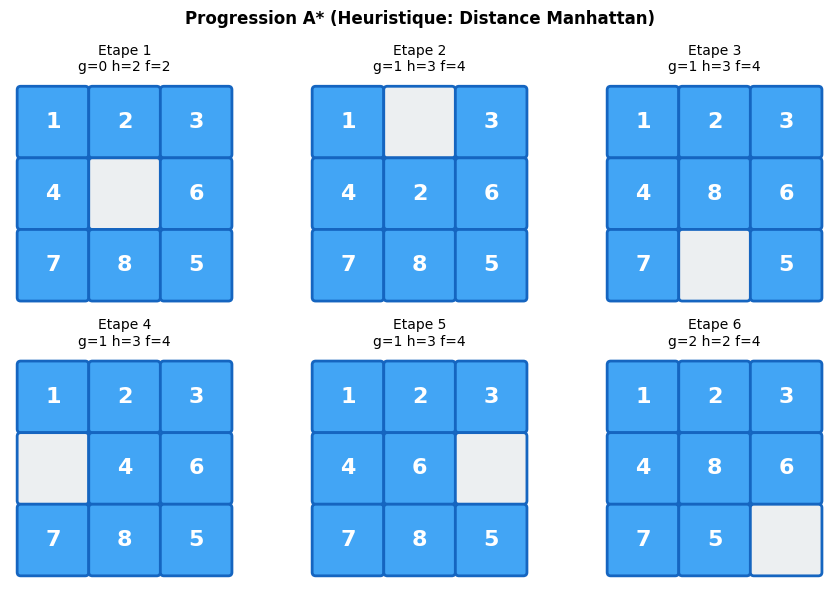

In [14]:
# --- Visualisation de l'exploration A* ---

def draw_puzzle_state(state, ax, title=""):
    """Dessine un etat du taquin."""
    for i in range(9):
        row, col = divmod(i, 3)
        value = state[i]

        if value == 0:
            color = '#ECEFF1'
            text = ''
        else:
            color = '#42A5F5'
            text = str(value)

        rect = mpatches.FancyBboxPatch(
            (col - 0.45, 2 - row - 0.45), 0.9, 0.9,
            boxstyle='round,pad=0.05',
            facecolor=color, edgecolor='#1565C0', linewidth=2
        )
        ax.add_patch(rect)
        if text:
            ax.text(col, 2 - row, text, ha='center', va='center',
                   fontsize=16, fontweight='bold', color='white')

    ax.set_xlim(-0.6, 2.6)
    ax.set_ylim(-0.6, 2.6)
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=10)


def visualize_astar_progression(problem, heuristic, max_steps=6):
    """Visualise la progression de A* pas a pas."""
    # Modifier A* pour capturer les etapes
    frontier = []
    counter = 0
    h_init = heuristic(problem.initial)
    root = Node(problem.initial, h=h_init)
    heapq.heappush(frontier, (root.f, counter, root))
    counter += 1

    g_scores = {root.state: 0}
    explored = set()
    steps = []

    while frontier and len(steps) < max_steps:
        f_val, _, node = heapq.heappop(frontier)

        if node.state in explored:
            continue

        steps.append({
            'state': node.state,
            'g': node.path_cost,
            'h': node.h,
            'f': node.f,
        })

        if problem.goal_test(node.state):
            break

        explored.add(node.state)

        for child in node.expand(problem, heuristic):
            if child.state not in explored:
                old_g = g_scores.get(child.state, float('inf'))
                if child.path_cost < old_g:
                    g_scores[child.state] = child.path_cost
                    heapq.heappush(frontier, (child.f, counter, child))
                    counter += 1

    # Afficher les etapes
    n = len(steps)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3 * ((n + 1) // 2), 6))
    if n == 1:
        axes = [[axes[0]]]
    axes = axes.flatten()

    for i, step in enumerate(steps):
        title = f"Etape {i+1}\ng={step['g']} h={step['h']} f={step['f']}"
        draw_puzzle_state(step['state'], axes[i], title)

    # Masquer les axes inutilises
    for i in range(n, len(axes)):
        axes[i].axis('off')

    fig.suptitle('Progression A* (Heuristique: Distance Manhattan)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


# Visualiser sur un probleme simple
simple_puzzle = EightPuzzleProblem((1, 2, 3, 4, 0, 6, 7, 8, 5))
visualize_astar_progression(simple_puzzle, h_manhattan, max_steps=6)

### Interprétation : Évolution de f(n) pendant la recherche

La visualisation montre comment A* explore les états :

| Étape | g(n) | h(n) | f(n) | Signification |
|-------|------|------|------|---------------|
| 1 (Initial) | 0 | élevé | f(0) | Estimation initiale |
| 2+ | croissant | décroissant | ≈ constant | A* tend à garder f croissant lentement |

**Observation** : A* explore d'abord les états avec $f(n)$ faible. Quand il développe un nœud, il génère des fils avec $g$ augmenté mais $h$ diminué (on se rapproche du but). La valeur $f$ reste donc approximativement stable le long du chemin optimal.


## 6. IDA* (Iterative Deepening A*)

L'étude de cas précédente a chiffré le prix de A\* : sur l'instance difficile
du 8-puzzle, il développe **143 839 nœuds**, tous conservés — A\* garde
l'ensemble des états explorés pour ne jamais y revenir, et sa complexité en
espace est $O(b^d)$. Sur un problème à grand facteur de branchement, c'est
donc la frontière qui épuise la mémoire bien avant que le temps ne devienne
gênant. IDA\* lève cette contrainte sans renoncer à l'optimalité.

### Principe

**IDA*** est la version à approfondissement itératif de A*. Il exécute des DFS limités par une borne sur $f(n)$ (plutôt que sur la profondeur).

À chaque itération :
1. DFS avec une limite $f_{\text{limit}}$
2. Si un nœud a $f(n) > f_{\text{limit}}$, on l'**élagué**
3. La prochaine itération utilise $f_{\text{limit}} = \min\{f(n) \mid n \text{ élagué}\}$

### Pourquoi IDA* ?

| Avantage | Explication |
|-----------|-------------|
| Mémoire | $O(bd)$ au lieu de $O(b^d)$ pour A* |
| Pas de file de priorité | DFS récursif plus simple |
| Même optimalité | A* avec la même heuristique |

**Inconvénient** : Re-explore les nœuds à chaque itération (comme IDDFS), mais l'overhead est modeste car la borne $f$ augmente généralement peu à chaque itération.


In [15]:
def ida_star_search(problem, heuristic, max_iterations=1000, verbose=False):
    """
    IDA* : Iterative Deepening A*.
    DFS avec limites sur f(n) = g(n) + h(n).
    """
    start_time = time.perf_counter()

    bound = heuristic(problem.initial)  # Premiere borne = h(initial)
    root = Node(problem.initial, h=bound)

    total_expanded = 0
    total_generated = 0
    explored_order = []
    iterations = 0
    # Memoire reellement tenue par IDA* : la profondeur de la pile recursive.
    # Le nombre d'iterations n'est PAS une mesure de memoire.
    max_stack_depth = 0

    def search(node, bound, min_excess):
        """
        DFS recursif avec limite sur f(n).
        Retourne (solution_node, new_bound).
        """
        nonlocal total_expanded, total_generated, max_stack_depth

        # node.depth est la profondeur du noeud dans l'arbre de l'iteration
        # courante : c'est exactement la profondeur de la pile recursive.
        max_stack_depth = max(max_stack_depth, node.depth + 1)

        f = node.f
        if f > bound:
            return None, f  # Coupe : retourner le f qui a provoque la coupure

        if problem.goal_test(node.state):
            return node, bound

        total_expanded += 1
        min_next_bound = float('inf')

        for child in node.expand(problem, heuristic):
            total_generated += 1
            result, child_bound = search(child, bound, min_next_bound)

            if result is not None:
                return result, bound

            min_next_bound = min(min_next_bound, child_bound)

        return None, min_next_bound

    # Boucle principale avec bornes croissantes
    while iterations < max_iterations:
        iterations += 1

        if verbose:
            print(f"  Iteration {iterations}: bound = {bound:.0f}")

        result, new_bound = search(root, bound, float('inf'))

        if result is not None:
            elapsed = (time.perf_counter() - start_time) * 1000
            # Reconstruire l'ordre d'exploration (approximatif)
            return SearchResult('IDA*', result, total_expanded,
                                total_generated, max_stack_depth,
                                elapsed, explored_order,
                                heuristic.__name__, iterations=iterations)

        if new_bound == float('inf'):
            break  # Espace entier explore

        bound = new_bound

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('IDA*', None, total_expanded, total_generated,
                        max_stack_depth, elapsed, explored_order,
                        heuristic.__name__, iterations=iterations)


print("Algorithme IDA* implemente.")

Algorithme IDA* implemente.


Test de IDA* sur le même problème de navigation.

**Lire la séquence de bornes.** La sortie montre le mécanisme d'IDA\* :
quatre itérations depth-first, chacune bornée par la plus petite valeur de
$f$ qui avait dépassé la borne précédente — **784, puis 993, puis 1018, puis
1075**. Chaque itération ré-explore l'arbre depuis la racine. L'échange
structurel se lit dans les compteurs : frontière maximale de **4** seulement
(contre 6 pour A\*), au prix de **8 nœuds explorés** (contre 3). IDA\* troque
la mémoire de la frontière contre du calcul répété — le bon marché quand la
frontière ne tient pas en mémoire, le mauvais quand les bornes se resserrent
(la comparaison complète ci-dessous le chiffrera).


In [16]:
# --- Test de IDA* sur le probleme Bordeaux -> Strasbourg ---

print("IDA* : Bordeaux -> Strasbourg")
print("=" * 60)
result_idastar = ida_star_search(problem_bs, h_to_strasbourg, verbose=True)
result_idastar.display()

IDA* : Bordeaux -> Strasbourg
  Iteration 1: bound = 784
  Iteration 2: bound = 993
  Iteration 3: bound = 1018
  Iteration 4: bound = 1075

--- IDA* [h] ---
  Chemin     : Bordeaux -> Paris -> Strasbourg
  Cout total : 1075
  Longueur   : 2 etapes
  Noeuds explores  : 8
  Noeuds generes   : 24
  Profondeur de pile max : 3
  Iterations             : 4
  Temps            : 0.12 ms


***
### Test de l'algorithme IDA*

L'algorithme **IDA\*** (Iterative Deepening A\*) combine les avantages de :
- **A\*** : heuristique pour guider la recherche
- **Iterative Deepening DFS** : économie de mémoire

Nous allons tester IDA* sur le problème de navigation routière (Bordeaux → Strasbourg) et comparer ses performances avec A* en termes de :
- Nombre de nœuds explorés
- Temps de calcul
- Qualité de la solution trouvée


### Interprétation : IDA* et les bornes croissantes

**Sortie obtenue** : IDA* effectue plusieurs itérations avec des bornes $f_{\text{limit}}$ croissantes.

| Itération | Borne $f_{\text{limit}}$ | Comportement |
|-----------|------------------------|--------------| 
| 1 | $h(\text{initial})$ | Élagage immédiat, augmenter la borne |
| 2 | $\min\{f\text{ élagués}\}$ | Élagage encore, augmenter |
| ... | ... | ... |
| k | $\geq f(\text{solution})$ | Solution trouvée ! |

**Points clés** :
1. IDA* trouve la **même solution** que A* (optimalité garantie)
2. Utilise **beaucoup moins de mémoire** que A* ($O(bd)$ vs $O(b^d)$)
3. L'overhead de ré-exploration est acceptable car la borne augmente rapidement


### Exercice : Chemin optimal Rennes -> Nice avec comparaison d'algorithmes

**Enonce** : trouvez le chemin optimal de Rennes a Nice en utilisant les trois algorithmes informes (Greedy, A*, IDA*), puis comparez.

**Questions** :
1. Créez le problème `GraphProblem('Rennes', 'Nice', france_graph)`
2. Créez l'heuristique `make_heuristic('Nice', france_coords)`
3. Lancez Greedy, A* et IDA* sur ce problème
4. Affichez un tableau comparatif (cout, noeuds explores, chemin)
5. Quel algorithme trouve le chemin optimal ? Lequel est le plus rapide ?

**Indice** : utilisez les fonctions `greedy_best_first_search`, `a_star_search` et `ida_star_search` déjà définies. Le chemin optimal passe par Rennes -> Nantes -> Bordeaux -> Toulouse -> Marseille -> Nice (1300 km).

In [17]:
# Exercice : Chemin optimal Rennes -> Nice avec comparaison d'algorithmes
# TODO etudiant : implementer la comparaison des 3 algorithmes
# Etape 1 : creer le probleme GraphProblem('Rennes', 'Nice', france_graph)
# Etape 2 : creer l'heuristique make_heuristic('Nice', france_coords)
# Etape 3 : lancer greedy_best_first_search, a_star_search et ida_star_search
# Etape 4 : afficher les resultats avec display() ou un tableau pandas
# Etape 5 : analyser quel algorithme est optimal et lequel est le plus rapide
result = None  # TODO etudiant : remplacer par la solution
print("Exercice a completer : comparaison Rennes -> Nice")

Exercice a completer : comparaison Rennes -> Nice


### Comparaison complète : Greedy vs A* vs IDA*

Comparons les trois algorithmes informés sur plusieurs problèmes pour observer leurs comportements relatifs.

**Trois régimes dans ce tableau.** Les quatre trajets ne racontent pas la
même histoire, et c'est le point de la cellule :

1. **Égalité des coûts** (`Bordeaux -> Strasbourg`, `Rennes -> Nice`,
   `Nantes -> Marseille`) : les trois algorithmes trouvent le même optimum
   (1075, 1300, 990) et seule varie l'exploration — 2/3/8, 5/9/**86**,
   3/5/24 nœuds.
2. **Sous-optimalité de Greedy** (`Lille -> Toulouse`) : le seul bloc où la
   colonne coût diverge — **1295** contre **1055**. Greedy longe la côte,
   l'optimum passe par Paris.
3. **Explosion d'IDA\*** (`Rennes -> Nice`) : 86 nœuds explorés et 247
   générés contre 5 et 9 — le prix des bornes rapprochées quand
   l'heuristique sous-estime beaucoup.

Un tableau où tous les coûts seraient égaux n'aurait rien démontré : c'est
précisément les blocs 2 et 3 qui donnent aux colonnes leur sens.


In [18]:
# --- Comparaison sur plusieurs problemes ---

test_cases = [
    ('Bordeaux', 'Strasbourg'),
    ('Rennes', 'Nice'),
    ('Lille', 'Toulouse'),
    ('Nantes', 'Marseille'),
]

all_results = []

for start, goal in test_cases:
    problem = GraphProblem(start, goal, france_graph)
    h = make_heuristic(goal, france_coords)

    greedy = greedy_best_first_search(problem, h)
    astar = a_star_search(problem, h)
    idastar = ida_star_search(problem, h)

    all_results.append({
        'start': start,
        'goal': goal,
        'greedy': greedy,
        'astar': astar,
        'idastar': idastar,
    })

# Tableau recapitulatif
print("Comparaison des algorithmes informes")
print("=" * 90)

for r in all_results:
    print(f"\n{r['start']} -> {r['goal']}")
    print("-" * 90)
    print(f"{'Algo':<10} {'Cout':>8} {'Explores':>10} {'Genere':>10} {'Chemin':<40}")
    print("-" * 90)

    for name, result in [('Greedy', r['greedy']), ('A*', r['astar']), ('IDA*', r['idastar'])]:
        path_str = ' -> '.join(result.path)
        if len(path_str) > 38:
            path_str = path_str[:35] + '...'
        print(f"{name:<10} {result.cost:>8.0f} {result.nodes_expanded:>10} "
              f"{result.nodes_generated:>10} {path_str:<40}")

Comparaison des algorithmes informes

Bordeaux -> Strasbourg
------------------------------------------------------------------------------------------
Algo           Cout   Explores     Genere Chemin                                  
------------------------------------------------------------------------------------------
Greedy         1075          2          8 Bordeaux -> Paris -> Strasbourg         
A*             1075          3         11 Bordeaux -> Paris -> Strasbourg         
IDA*           1075          8         24 Bordeaux -> Paris -> Strasbourg         

Rennes -> Nice
------------------------------------------------------------------------------------------
Algo           Cout   Explores     Genere Chemin                                  
------------------------------------------------------------------------------------------
Greedy         1300          5         15 Rennes -> Nantes -> Bordeaux -> Tou...  
A*             1300          9         28 Rennes -> Nantes ->

### Interprétation : Synthèse des performances

**Observations générales** :

| Algorithme | Optimalité | Nœuds explorés | Mémoire | Cas d'usage |
|------------|-----------|-----------------|----------|-------------|
| **Greedy** | Non | Variable (souvent moins) | $O(b^m)$ | Solutions rapides, qualité acceptable |
| **A*** | Oui | Modéré | $O(b^d)$ | Référence, optimalité requise |
| **IDA*** | Oui | **Plus que A*** (re-expansions) | $O(bd)$ | Mémoire limitée |

**À noter.** Sur ce graphe, IDA* n'est pas « similaire à A* » en nœuds explorés : il en explore **2,7 à 9,6 fois plus** que A* sur chaque trajet (Rennes→Nice : **86** contre **9** ; Nantes→Marseille : 24 contre 5 ; Lille→Toulouse : 14 contre 4 ; Bordeaux→Strasbourg : 8 contre 3). L'avantage mémoire d'IDA* ($O(bd)$ au lieu de $O(b^d)$) se paie par la ré-expansion répétée des nœuds peu profonds à chaque palier d'approfondissement itératif : le compromis est **mémoire contre temps**, pas « temps similaire + moins de mémoire ». IDA* s'impose surtout sur des espaces de recherche très profonds où la mémoire d'A* devient prohibitif.

**Recommandations pratiques** :
- **A*** : choix par défaut quand la mémoire n'est pas un problème
- **IDA*** : pour les espaces de recherche très profonds ou quand la mémoire est limitée
- **Greedy** : quand la vitesse est prioritaire et une solution sous-optimale est acceptable


## 7. Conception d'heuristiques : Admissibilité et Consistance

La qualité d'une heuristique détermine l'efficacité des algorithmes informés. Une bonne heuristique doit être à la fois facile à calculer et proche du coût optimal.

**L'arc de cette section.** Trois propriétés y sont définies, puis
confrontées : l'**admissibilité** ($h \le h^*$, la promesse qui fonde
l'optimalité d'A\*), la **consistance** (variante plus forte, $h(n) \le
c(n, n') + h(n')$ sur chaque arête), et la **dominance** (comparer deux
heuristiques admissibles entre elles). La section ne se contente pas des
définitions : elle se termine par un **contre-exemple mesuré** où une
heuristique admissible mais non consistante fait rendre à la variante sans
ré-open de ce notebook un chemin de **4.0** pour un optimum de **3.5**
(14 % de trop) — la distinction entre les deux propriétés n'est pas un
raffinement théorique, elle se paie en kilomètres.


### Admissibilité

Une heuristique $h$ est **admissible** si elle ne surestime jamais le coût réel :

$$\forall n, \quad h(n) \leq h^*(n)$$

où $h^*(n)$ est le coût optimal réel de $n$ au but.

| Heuristique | Admissible ? | Justification |
|-------------|--------------|----------------|
| Distance à vol d'oiseau | Oui | Le chemin le plus court est la ligne droite |
| Nombre de tuiles mal placées (8-puzzle) | Oui | Chaque tuile nécessite au moins 1 mouvement |
| Distance / 2 | Oui | Si l'heuristique originale est admissible, la diviser aussi |
| Distance × 2 | Non | Peut surestimer le coût réel |

**Théorème** : A* avec une heuristique **consistante** est optimal (trouve une solution de coût minimal) — c'est la condition qui correspond à la variante Graph-Search implémentée dans ce notebook, qui ferme définitivement les états explorés.

Avec une heuristique seulement **admissible**, la garantie d'optimalité exige une variante qui **ré-ouvre** un état fermé lorsqu'un meilleur $g$ arrive. Le contre-exemple ci-dessous le montre en pratique : une heuristique admissible partout, et pourtant un chemin sous-optimal.


### Consistance (Monotonie)

Une heuristique $h$ est **consistante** si pour tout nœud $n$ et tout successeur $n'$ :

$$h(n) \leq c(n, a, n') + h(n')$$

où $c(n, a, n')$ est le coût de l'action de $n$ vers $n'$.

**Intuition** : Le coût estimé jusqu'au but ne doit pas diminuer de plus que le coût de déplacement — autrement dit, l'estimation doit évoluer de façon monotone.

| Propriété | Admissible | Consistante |
|-----------|------------|-------------|
| Définition | $h(n) \leq h^*(n)$ | $h(n) \leq c(n, n') + h(n')$ |
| Relation | Consistante ⇒ Admissible | Admissible n'implique pas consistante |
| Effet sur A* | Insuffisante pour cette variante (contre-exemple ci-dessous) | Optimalité + pas de *re-open* |

**Exemple** : Pour le 8-puzzle :
- « Tuiles mal placées » (**case vide exclue**) est admissible **et** consistante : un mouvement fait glisser une seule tuile numérotée, donc le compte varie d'au plus 1
- « Distance Manhattan » est admissible **et** consistante


### Contre-exemple : admissible ne suffit pas (pour cette variante de A*)

L'implémentation `a_star_search` (section 4) ferme définitivement chaque état exploré : un meilleur $g$ arrivant plus tard sur un état fermé est ignoré. Pour **cette** variante, la consistance est la condition qui **achète** l'optimalité — l'admissibilité seule ne suffit pas.

Le graphe à quatre nœuds ci-dessous le démontre : l'heuristique est admissible **partout** (vérifiée exhaustivement contre $h^*$), deux arcs violent la consistance, et A* rend un chemin de coût **4** là où l'optimum est **3,5**.


In [19]:
# --- Contre-exemple : h admissible mais NON consistante -> A* (sans re-open) sous-optimal ---

# Graphe oriente 4 noeuds. Optimum : S -> B -> A -> G = 1 + 0.5 + 2 = 3.5
counter_graph = {
    'S': {'A': 2.0, 'B': 1.0},
    'B': {'A': 0.5},
    'A': {'G': 2.0},
    'G': {},
}

def h_inconsistent(state):
    """h(S)=3.5, h(B)=2.5, h(A)=0, h(G)=0 : admissible partout, non consistante."""
    return {'S': 3.5, 'B': 2.5, 'A': 0.0, 'G': 0.0}[state]

def dijkstra_hstar(graph, goal):
    """Couts optimaux exacts h*(n) vers le but (Dijkstra sur le graphe inverse)."""
    reverse = {n: {} for n in graph}
    for u, nbrs in graph.items():
        for v, c in nbrs.items():
            reverse.setdefault(v, {})[u] = c
    dist = {goal: 0.0}
    heap = [(0.0, goal)]
    while heap:
        d, u = heapq.heappop(heap)
        if d > dist.get(u, float('inf')):
            continue
        for v, c in reverse.get(u, {}).items():
            nd = d + c
            if nd < dist.get(v, float('inf')):
                dist[v] = nd
                heapq.heappush(heap, (nd, v))
    return dist

h_star = dijkstra_hstar(counter_graph, 'G')

# 1) Admissibilite : verifiee EXHAUSTIVEMENT sur les 4 etats (pas un echantillon)
adm = {n: h_inconsistent(n) <= h_star[n] for n in counter_graph}
print("admissible partout ?", all(adm.values()),
      " ", {n: (h_inconsistent(n), h_star[n]) for n in counter_graph})

# 2) Consistance : les arcs qui violent h(n) <= c(n, n') + h(n')
violations = [
    (u, v, c) for u, nbrs in counter_graph.items() for v, c in nbrs.items()
    if h_inconsistent(u) > c + h_inconsistent(v)
]
print("arcs violant la consistance :",
      [(u, v, f"c={c}", f"h({u})={h_inconsistent(u)} > {c + h_inconsistent(v):.1f}")
       for u, v, c in violations])

# 3) A* du notebook (fermeture definitive) contre l'optimum Dijkstra/UCS
problem_ce = GraphProblem('S', 'G', counter_graph)
res_astar = a_star_search(problem_ce, h_inconsistent)
print(f"A* du notebook          -> {' -> '.join(res_astar.path)} {res_astar.cost}")
print(f"Optimum (Dijkstra/UCS)  -> S -> B -> A -> G {h_star['S']}")
print(f"Ecart : A* rend {res_astar.cost} pour un optimum de {h_star['S']}"
      f" ({(res_astar.cost - h_star['S']) / h_star['S']:.0%} de trop)")


admissible partout ? True   {'S': (3.5, 3.5), 'B': (2.5, 2.5), 'A': (0.0, 2.0), 'G': (0.0, 0.0)}
arcs violant la consistance : [('S', 'A', 'c=2.0', 'h(S)=3.5 > 2.0'), ('B', 'A', 'c=0.5', 'h(B)=2.5 > 0.5')]
A* du notebook          -> S -> A -> G 4.0
Optimum (Dijkstra/UCS)  -> S -> B -> A -> G 3.5
Ecart : A* rend 4.0 pour un optimum de 3.5 (14% de trop)


### Interprétation : pourquoi l'admissibilité ne suffit pas ici

**Ce qui s'est passé** : A* développe S, puis A (f = 2), puis B (f = 3,5). Depuis B, un chemin de coût 1 + 0,5 = 1,5 vers A **améliorerait** le g de A (2 → 1,5) — mais A est déjà fermé, l'amélioration est ignorée. Le but est ensuite atteint via S → A → G de coût 4, alors que S → B → A → G coûte 3,5.

**La leçon** : l'admissibilité ($h \leq h^*$) garantit que $f$ ne sous-estime jamais le coût d'un chemin optimal passant par $n$ — mais un nœud fermé avec un $g$ non optimal ne revient jamais en frontière, et la garantie ne peut plus s'exercer. La consistance ($h(n) \leq c(n, n') + h(n')$) maintient les $f$ monotones le long des chemins : le premier développement de chaque état est déjà optimal, ce qui rend la fermeture définitive **sans risque**.

Ce contre-exemple est le **symétrique** de celui de la section 9 (exercice 2, #12465) : là, une heuristique **non admissible** rendait A* sous-optimal ; ici, l'heuristique est admissible **partout** et A* est sous-optimal quand même. Le couple forme la leçon complète : ce qui achète l'optimalité à **cette** variante de Graph-Search, c'est la **consistance**.


### Dominance entre heuristiques

Une heuristique $h_1$ **domine** $h_2$ si :

$$\forall n, \quad h_1(n) \geq h_2(n)$$

et l'inégalité est stricte pour au moins un nœud.

**Théorème** : Si $h_1$ domine $h_2$, alors A* avec $h_1$ n'explore jamais plus de nœuds que A* avec $h_2$.

| Heuristique | Valeur typique | Dominance |
|-------------|----------------|-----------|
| $h = 0$ | Toujours 0 | Dominée par toutes |
| Tuiles mal placées | $\leq 8$ | Dominée par Manhattan |
| Distance Manhattan | $\leq 20$ environ | Domine « mal placées » |
| Coût optimal $h^*$ | Exacte | Domine tout |

> **Note** : Une heuristique dominante est toujours meilleure (ou égale) en termes de nœuds explorés, mais peut être plus coûteuse à calculer.


## 8. Tableau récapitulatif : Algorithmes informés vs non informés

Synthétisons nos connaissances en comparant tous les algorithmes étudiés (Search-2 et Search-3).

**Comment lire ce tableau** : en séparant ce qui est une propriété
**d'instance** de ce qui est une propriété **de classe**. La colonne des
nœuds explorés appartient à la première — BFS ne développe que **2 nœuds**
ici parce que le chemin optimal est court et trouvé tôt, coup de chance de ce
graphe précis. Les colonnes **Complet** et **Optimal** appartiennent à la
seconde : BFS y reste « Non optimal » *en tant que classe d'algorithme*, même
sur une instance où il trouve 1075. Les quatre algorithmes affichent le même
coût de 1075 km sur ce trajet ; la hiérarchie des garanties, elle, ne dépend
pas du trajet — c'est précisément ce qui la rend utile.



Tableau recapitulatif : Algorithmes de recherche
Algorithme           Complet            Optimal Cout  Noeuds explores Temps (ms)
       BFS               Oui                Non 1075                2       0.04
       UCS               Oui                Oui 1075               10       0.07
    Greedy Oui (graphe fini)                Non 1075                2       0.03
        A*               Oui Oui (h admissible) 1075                3       0.03

Note : Greedy est execute ici en variante graph-search (ensemble ferme),
donc complet sur graphe fini a successeurs finis. La variante tree-search
(sans detection de cycles) n'est pas complete. Greedy n'est optimal dans
aucune des deux variantes.


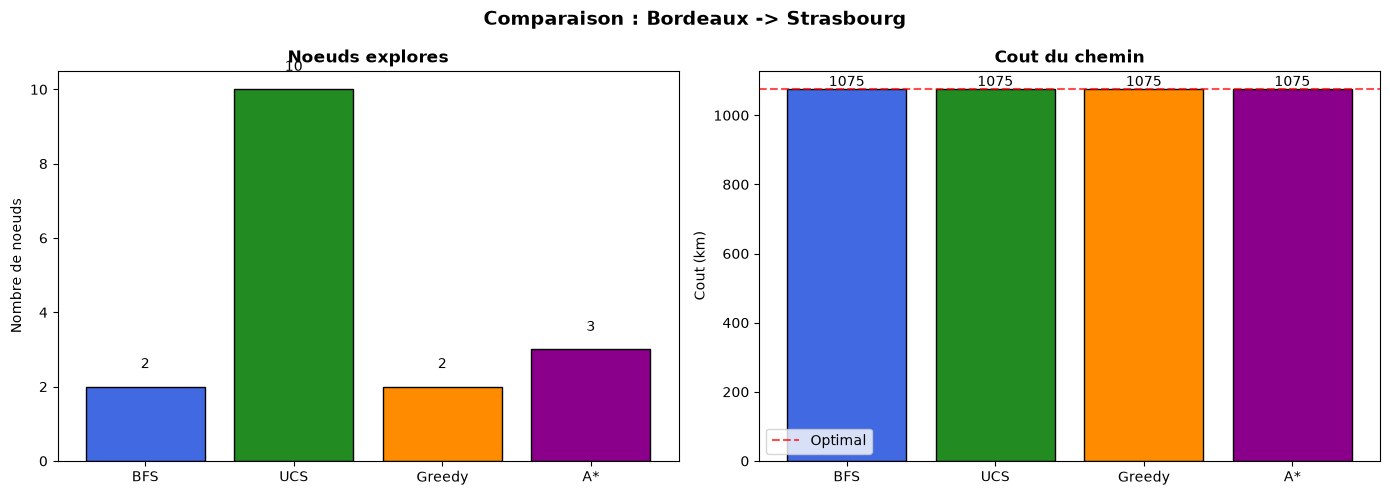

In [20]:
# --- Tableau recapitulatif complet ---

# Import des algorithmes non informes depuis Search-2
def breadth_first_search(problem, verbose=False):
    """BFS pour comparaison (implementation simplifiee)."""
    start_time = time.perf_counter()
    node = Node(problem.initial)
    if problem.goal_test(node.state):
        elapsed = (time.perf_counter() - start_time) * 1000
        return SearchResult('BFS', node, 0, 0, 1, elapsed)

    frontier = deque([node])
    frontier_states = {node.state}
    explored = set()
    explored_order = []
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        current = frontier.popleft()
        frontier_states.discard(current.state)
        explored.add(current.state)
        explored_order.append(current.state)
        nodes_expanded += 1

        for child in current.expand(problem):
            nodes_generated += 1
            if child.state not in explored and child.state not in frontier_states:
                if problem.goal_test(child.state):
                    elapsed = (time.perf_counter() - start_time) * 1000
                    return SearchResult('BFS', child, nodes_expanded,
                                        nodes_generated, max_frontier,
                                        elapsed, explored_order)
                frontier.append(child)
                frontier_states.add(child.state)
                max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('BFS', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order)


def uniform_cost_search(problem, verbose=False):
    """UCS pour comparaison."""
    start_time = time.perf_counter()
    node = Node(problem.initial)
    frontier = []
    counter = 0
    heapq.heappush(frontier, (node.path_cost, counter, node))
    counter += 1
    frontier_map = {node.state: node.path_cost}
    explored = set()
    explored_order = []
    nodes_expanded = 0
    nodes_generated = 0
    max_frontier = 1

    while frontier:
        cost, _, current = heapq.heappop(frontier)

        if problem.goal_test(current.state):
            elapsed = (time.perf_counter() - start_time) * 1000
            return SearchResult('UCS', current, nodes_expanded,
                                nodes_generated, max_frontier,
                                elapsed, explored_order)

        if current.state in explored:
            continue

        explored.add(current.state)
        explored_order.append(current.state)
        nodes_expanded += 1

        for child in current.expand(problem):
            nodes_generated += 1
            if child.state not in explored:
                old_cost = frontier_map.get(child.state, float('inf'))
                if child.path_cost < old_cost:
                    heapq.heappush(frontier, (child.path_cost, counter, child))
                    counter += 1
                    frontier_map[child.state] = child.path_cost
                    max_frontier = max(max_frontier, len(frontier))

    elapsed = (time.perf_counter() - start_time) * 1000
    return SearchResult('UCS', None, nodes_expanded, nodes_generated,
                        max_frontier, elapsed, explored_order)


# Comparer tous les algorithmes
test_problem = GraphProblem('Bordeaux', 'Strasbourg', france_graph)
h = make_heuristic('Strasbourg', france_coords)

results = {
    'BFS': breadth_first_search(test_problem),
    'UCS': uniform_cost_search(test_problem),
    'Greedy': greedy_best_first_search(test_problem, h),
    'A*': a_star_search(test_problem, h),
}

# Creer le tableau
summary_data = []
for name, result in results.items():
    summary_data.append({
        'Algorithme': name,
        'Complet': ('Oui' if name in ['BFS', 'UCS', 'A*']
                    else 'Oui (graphe fini)' if name == 'Greedy'
                    else 'Non'),
        'Optimal': 'Oui' if name == 'UCS' else ('Oui (h admissible)' if name == 'A*' else 'Non'),
        'Cout': f"{result.cost:.0f}",
        'Noeuds explores': result.nodes_expanded,
        'Temps (ms)': f"{result.elapsed_ms:.2f}",
    })

summary_df = pd.DataFrame(summary_data)
print("\nTableau recapitulatif : Algorithmes de recherche")
print("=" * 80)
print(summary_df.to_string(index=False))
print()
print("Note : Greedy est execute ici en variante graph-search (ensemble ferme),")
print("donc complet sur graphe fini a successeurs finis. La variante tree-search")
print("(sans detection de cycles) n'est pas complete. Greedy n'est optimal dans")
print("aucune des deux variantes.")

# Visualiser
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Noeuds explores
names = list(results.keys())
explored_counts = [results[n].nodes_expanded for n in names]
colors = ['#4169E1', '#228B22', '#FF8C00', '#8B008B']
axes[0].bar(names, explored_counts, color=colors, edgecolor='black')
axes[0].set_ylabel('Nombre de noeuds')
axes[0].set_title('Noeuds explores', fontweight='bold')
for i, v in enumerate(explored_counts):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontsize=10)

# Cout du chemin
costs = [results[n].cost for n in names]
axes[1].bar(names, costs, color=colors, edgecolor='black')
axes[1].set_ylabel('Cout (km)')
axes[1].set_title('Cout du chemin', fontweight='bold')
for i, v in enumerate(costs):
    axes[1].text(i, v + 10, f"{v:.0f}", ha='center', fontsize=10)

# Marquer l'optimal
optimal_cost = min(costs)
axes[1].axhline(y=optimal_cost, color='red', linestyle='--', alpha=0.7, label='Optimal')
axes[1].legend()

plt.suptitle('Comparaison : Bordeaux -> Strasbourg', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interprétation : Synthèse des algorithmes de recherche

**Tableau récapitulatif des propriétés** :

| Algorithme | Complet | Optimal | Stratégie | Heuristique |
|------------|---------|---------|-----------|-------------|
| BFS | Oui | Oui* | Par niveaux | Non |
| DFS | Non | Non | En profondeur | Non |
| UCS | Oui | Oui | Par coût croissant | Non |
| IDDFS | Oui | Oui* | Profondeur itérée | Non |
| Greedy (tree search, sans ensemble fermé) | Non | Non | Par $h(n)$ | Oui |
| Greedy (graph-search avec ensemble fermé — implémentation de ce carnet) | Oui*** | Non | Par $h(n)$ | Oui |
| A* | Oui | Oui** | Par $g(n)+h(n)$ | Oui |
| IDA* | Oui | Oui** | $f(n)$ itérée | Oui |

\* Optimal uniquement avec coûts uniformes.  
\*\* A\* : optimal avec heuristique **consistante** (variante Graph-Search sans ré-ouverture, contre-exemple §7) ; IDA\* : optimal avec heuristique admissible (pas d'ensemble fermé).  
\*\*\* Complétude de Greedy : la variante *tree search* (sans ensemble fermé) n'est pas complète ; la variante *graph-search* avec ensemble fermé — celle implémentée dans ce carnet (§3) — est complète **sur graphe fini à successeurs finis**. C'est la valeur portée par la ligne « Greedy (graph-search…) » du tableau ci-dessus.

**Guide de choix pratique** :

| Situation | Algorithme recommandé |
|-----------|----------------------|
| Pas d'heuristique, coûts uniformes | BFS ou IDDFS |
| Pas d'heuristique, coûts variables | UCS |
| Heuristique disponible, assez de mémoire | A* |
| Heuristique disponible, mémoire limitée | IDA* |
| Solution rapide acceptable | Greedy |


## 9. Exemples guides et exercices

### Exercice 1 : Vérifier l'admissibilité

Pour le problème d'itinéraire, vérifiez que la distance à vol d'oiseau est bien une heuristique admissible. Pour cela, comparez la distance à vol d'oiseau avec la distance réelle (chemin le plus court selon UCS) pour toutes les paires de villes du graphe.

**Critère de contrôle de l'exercice 1.** La vérité terrain à utiliser est
UCS : le plus court chemin calculé par recherche uniforme pour chaque paire
de villes. L'exercice est réussi quand la vérification « $h(n) \le$
coût réel » est passée sur **toutes** les paires du graphe — pas seulement
celles qui ont une route directe (rappel de la section 2 : les `N/A` du
premier tableau masquaient exactement ce cas).

**Feuille de route des exemples guidés** : l'exemple guide 2 construit une
heuristique non admissible (h × 2) et mesure d'abord une issue « par chance »
(1075 km quand même) — avant que les deux contre-exemples qui suivent
(`Grenoble -> Marseille` : 530 contre 425 km ; `Marseille -> Rennes` :
1275 contre 1100 km) montrent que la chance n'est pas une méthode.
L'exemple guide 3 construit l'heuristique MST pour le TSP — admissible **et**
consistante, avec des valeurs mesurées (1224, 1527, 410 km) — avant les
exercices de pathfinding sur grille.


In [21]:
# --- Exercice 1 : Vérifier l'admissibilité ---

def check_admissibility(graph, coords):
    """
    Vérifie que la distance à vol d'oiseau est admissible pour toutes les paires
    de villes du graphe, en comparant h(n) avec le coût réel du plus court chemin.
    """
    return None  # TODO étudiant : implémenter check_admissibility
admissible = check_admissibility(france_graph, france_coords)


### Exemple guide 2 : Créer une heuristique non admissible

Modifiez la distance à vol d'oiseau pour créer une heuristique non admissible (par exemple, en multipliant par 2). Observez comment A* se comporte avec cette heuristique. Trouve-t-il toujours une solution ? Est-elle optimale ?


In [22]:
# --- Exercice 2 : Heuristique non admissible ---

def make_inadmissible_heuristic(goal, coords, factor=2.0):
    """Crée une heuristique non admissible en multipliant la distance par factor."""
    def h(state):
        return factor * euclidean_distance(state, goal, coords)
    h.__name__ = f"h_x{factor}"
    return h


# Heuristique admissible (référence)
h_admissible = make_heuristic("Strasbourg", france_coords)

# Heuristique non admissible (×2)
h_inadmissible = make_inadmissible_heuristic("Strasbourg", france_coords, factor=2.0)

# Comparer A* avec les deux heuristiques
print("A* avec heuristique admissible vs non admissible")
print("=" * 70)

result_adm   = a_star_search(problem_bs, h_admissible)
result_inadm = a_star_search(problem_bs, h_inadmissible)

print(f"Admissible   : coût={result_adm.cost:.0f} km, nœuds={result_adm.nodes_expanded}, chemin={result_adm.path}")
print(f"Non admissible (×2) : coût={result_inadm.cost:.0f} km, nœuds={result_inadm.nodes_expanded}, chemin={result_inadm.path}")
print()

optimal = result_adm.cost
print(f"Coût optimal (A* admissible) : {optimal:.0f} km")
if abs(result_inadm.cost - optimal) < 0.1:
    print("→ Par chance, la solution non admissible est ici optimale.")
else:
    diff = result_inadm.cost - optimal
    print(f"→ La solution non admissible est SOUS-OPTIMALE : {diff:.0f} km de plus ({diff/optimal*100:.1f}%).")

print()
print("Analyse :")
print("  Une heuristique non admissible pousse A* à explorer moins de nœuds")
print("  (car elle semble estimer des coûts élevés et coupe plus tôt la frontière),")
print("  mais au prix de l'optimalité : A* peut rater le chemin le plus court.")


A* avec heuristique admissible vs non admissible
Admissible   : coût=1075 km, nœuds=3, chemin=['Bordeaux', 'Paris', 'Strasbourg']
Non admissible (×2) : coût=1075 km, nœuds=2, chemin=['Bordeaux', 'Paris', 'Strasbourg']

Coût optimal (A* admissible) : 1075 km
→ Par chance, la solution non admissible est ici optimale.

Analyse :
  Une heuristique non admissible pousse A* à explorer moins de nœuds
  (car elle semble estimer des coûts élevés et coupe plus tôt la frontière),
  mais au prix de l'optimalité : A* peut rater le chemin le plus court.


### Quand la chance tourne : le contre-exemple attendu

Sur Bordeaux → Strasbourg, l'heuristique ×2 a eu de la chance. La question posée plus haut —
« Est-elle optimale ? » — mérite mieux qu'un lancer de dés : cherchons dans le **même graphe**
un trajet où ×2 fait dévier A*. La cellule suivante fait le **balayage systématique** des
**132 trajets** du graphe (les 12 × 11 paires ordonnées) et compare A* admissible à A* ×2 sur
chacun. Résultat : **5 trajets déviants** sur 132 ; le plus net est **Grenoble → Marseille**,
exactement le miroir du piège Greedy de la section 4 : là, Greedy se laissait attirer vers
l'intérieur des terres (Grenoble, Lyon) ; ici, c'est la côte qui « semble » proche — **Nice**
n'est qu'à 158 km de Marseille à vol d'oiseau, contre 276 pour Lyon — alors que la route de
la côte coûte 330 km contre 110 via Lyon.

In [23]:
# --- Balayage systematique : quand h x2 fait deriver A* ? ---
# Compare A* (h admissible) vs A* (h x2) sur les 12*11=132 paires ordonnees
# du graphe France, pour chiffrer la promesse "plus rapide, mais optimale ?".

_cities = list(france_graph.keys())
_pairs_total = len(_cities) * (len(_cities) - 1)
_deviants = []  # (src, dst, cost_adm, cost_x2, gain_x2_pct)
_adm_cost_sum = 0
_x2_cost_sum = 0
for _src in _cities:
    for _dst in _cities:
        if _src == _dst:
            continue
        _prob = GraphProblem(_src, _dst, france_graph)
        _h_adm = make_heuristic(_dst, france_coords)
        _h_x2 = make_inadmissible_heuristic(_dst, france_coords, factor=2.0)
        _r_adm = a_star_search(_prob, _h_adm)
        _r_x2 = a_star_search(_prob, _h_x2)
        _adm_cost_sum += _r_adm.cost
        _x2_cost_sum += _r_x2.cost
        if abs(_r_x2.cost - _r_adm.cost) > 0.1:
            _gain_pct = (_r_x2.cost - _r_adm.cost) / _r_adm.cost * 100
            _deviants.append((_src, _dst, _r_adm.cost, _r_x2.cost, _gain_pct))

# Trier par surcout decroissant (le plus net en tete)
_deviants.sort(key=lambda t: -t[4])

print(f"Balayage des {_pairs_total} trajets du graphe :")
print(f"  A* (admissible)      : cout total = {_adm_cost_sum:.0f} km")
print(f"  A* (h x2)            : cout total = {_x2_cost_sum:.0f} km")
print(f"  Surcout global       : +{_x2_cost_sum - _adm_cost_sum:.0f} km ({( _x2_cost_sum - _adm_cost_sum) / _adm_cost_sum * 100:.2f}%)")
print(f"  Trajets deviants     : {len(_deviants)} / {_pairs_total}")
print()
if _deviants:
    print("Detail des trajets ou h x2 fait deriver A* (tries par surcout %) :")
    print(f"  {'src':12s} -> {'dst':12s}   {'admissible':>10s}  {'h x2':>10s}   {'+km':>5s}  {'+%':>6s}")
    for _s, _d, _ca, _cx, _gp in _deviants:
        print(f"  {_s:12s} -> {_d:12s}   {_ca:>10.0f}  {_cx:>10.0f}   {(_cx - _ca):>+5.0f}  {_gp:>+6.1f}")
    print()
    _worst = _deviants[0]
    print(f"Contre-exemple le plus net : {_worst[0]} -> {_worst[1]}")
    print(f"  Cout admissible : {_worst[2]:.0f} km")
    print(f"  Cout h x2       : {_worst[3]:.0f} km  (+{_worst[3] - _worst[2]:.0f} km, +{_worst[4]:.1f}%)")


Balayage des 132 trajets du graphe :
  A* (admissible)      : cout total = 91850 km
  A* (h x2)            : cout total = 92475 km
  Surcout global       : +625 km (0.68%)
  Trajets deviants     : 5 / 132

Detail des trajets ou h x2 fait deriver A* (tries par surcout %) :
  src          -> dst            admissible        h x2     +km      +%
  Grenoble     -> Marseille             425         530    +105   +24.7
  Lille        -> Nantes                610         710    +100   +16.4
  Marseille    -> Rennes               1100        1275    +175   +15.9
  Rennes       -> Strasbourg            985        1130    +145   +14.7
  Nice         -> Rennes               1300        1400    +100    +7.7

Contre-exemple le plus net : Grenoble -> Marseille
  Cout admissible : 425 km
  Cout h x2       : 530 km  (+105 km, +24.7%)


In [24]:
# --- Contre-exemple : h non admissible fait rater l'optimum a A* ---
# Grenoble -> Marseille : le meme graphe, la meme heuristique x2 -- mais la chance tourne.
problem_gm = GraphProblem("Grenoble", "Marseille", france_graph)
h_gm_ok  = make_heuristic("Marseille", france_coords)
h_gm_bad = make_inadmissible_heuristic("Marseille", france_coords, factor=2.0)

r_gm_ok  = a_star_search(problem_gm, h_gm_ok)
r_gm_bad = a_star_search(problem_gm, h_gm_bad)

print("Contre-exemple : Grenoble -> Marseille (admissible vs non admissible)")
print("=" * 70)
counter_example_df = pd.DataFrame([
    {
        'Heuristique': 'h (admissible)',
        'Chemin': ' -> '.join(r_gm_ok.path),
        'Cout (km)': r_gm_ok.cost,
        'Noeuds explores': r_gm_ok.nodes_expanded,
    },
    {
        'Heuristique': 'h x2 (non admissible)',
        'Chemin': ' -> '.join(r_gm_bad.path),
        'Cout (km)': r_gm_bad.cost,
        'Noeuds explores': r_gm_bad.nodes_expanded,
    },
])
print(counter_example_df.to_string(index=False))

optimal = r_gm_ok.cost
diff = r_gm_bad.cost - optimal
print()
print(f"Cout optimal (A* admissible) : {optimal:.0f} km")
if diff > 0.1:
    print(f"A* NON admissible : SOUS-OPTIMAL de {diff:.0f} km ({diff / optimal * 100:.1f}% de plus).")
else:
    print("A* NON admissible : optimal ici aussi.")

# Pourquoi : decomposer f = g + h aux deux successeurs de Grenoble.
print()
print(" Mecanisme : le classement de f bascule quand h est doublee")
f_decomp = pd.DataFrame([
    {
        'Successeur': 'Lyon  (route 110 km, h=276)',
        'f = g + h   (h honnete)': 110 + euclidean_distance("Lyon", "Marseille", france_coords),
        'f = g + 2h  (h x2)': 110 + 2 * euclidean_distance("Lyon", "Marseille", france_coords),
    },
    {
        'Successeur': 'Nice  (route 330 km, h=158)',
        'f = g + h   (h honnete)': 330 + euclidean_distance("Nice", "Marseille", france_coords),
        'f = g + 2h  (h x2)': 330 + 2 * euclidean_distance("Nice", "Marseille", france_coords),
    },
])
print(f_decomp.to_string(index=False, float_format=lambda v: f"{v:7.0f}"))
print()
print("Avec h honnete, Lyon gagne (f plus petit) -> A* part par Lyon et trouve 425 km.")
print("Avec h x2, le classement S'INVERSE : l'avantage vol d'oiseau de Nice, double,")
print("ecrase les 220 km de route supplementaires -> A* s'engage par Nice : 530 km.")

Contre-exemple : Grenoble -> Marseille (admissible vs non admissible)
          Heuristique                        Chemin  Cout (km)  Noeuds explores
       h (admissible) Grenoble -> Lyon -> Marseille        425                2
h x2 (non admissible) Grenoble -> Nice -> Marseille        530                2

Cout optimal (A* admissible) : 425 km
A* NON admissible : SOUS-OPTIMAL de 105 km (24.7% de plus).

 Mecanisme : le classement de f bascule quand h est doublee
                 Successeur  f = g + h   (h honnete)  f = g + 2h  (h x2)
Lyon  (route 110 km, h=276)                      386                 663
Nice  (route 330 km, h=158)                      488                 645

Avec h honnete, Lyon gagne (f plus petit) -> A* part par Lyon et trouve 425 km.
Avec h x2, le classement S'INVERSE : l'avantage vol d'oiseau de Nice, double,
ecrase les 220 km de route supplementaires -> A* s'engage par Nice : 530 km.


### Second témoin : la vitesse achetée au prix de l'optimalité

Le contre-exemple précédent est un piège de **qualité** (même nombre de nœuds). Le trajet
**Marseille → Rennes** cumule les deux effets annoncés plus haut : l'heuristique ×2 y fait
explorer **deux fois moins** de nœuds — c'est la promesse séduisante — tout en rendant un
chemin **175 km plus long**. C'est le vrai visage du compromis : la sur-estimation resserre
la frontière (A* « coupe plus tôt », il se comporte en Greedy), et Greedy n'est pas optimal.

In [25]:
# --- Second temoin : Marseille -> Rennes, vitesse contre optimalite ---
problem_mr = GraphProblem("Marseille", "Rennes", france_graph)
h_mr_ok  = make_heuristic("Rennes", france_coords)
h_mr_bad = make_inadmissible_heuristic("Rennes", france_coords, factor=2.0)

r_mr_ok  = a_star_search(problem_mr, h_mr_ok)
r_mr_bad = a_star_search(problem_mr, h_mr_bad)

print("Second temoin : Marseille -> Rennes")
print("=" * 70)
counter_example_df = pd.DataFrame([
    {
        'Heuristique': 'h (admissible)',
        'Chemin': ' -> '.join(r_mr_ok.path),
        'Cout (km)': r_mr_ok.cost,
        'Noeuds explores': r_mr_ok.nodes_expanded,
    },
    {
        'Heuristique': 'h x2 (non admissible)',
        'Chemin': ' -> '.join(r_mr_bad.path),
        'Cout (km)': r_mr_bad.cost,
        'Noeuds explores': r_mr_bad.nodes_expanded,
    },
])
print(counter_example_df.to_string(index=False))
diff = r_mr_bad.cost - r_mr_ok.cost
print()
print(f"Sous-optimal de {diff:.0f} km (+{diff / r_mr_ok.cost * 100:.1f}%), "
      f"avec {r_mr_ok.nodes_expanded} -> {r_mr_bad.nodes_expanded} noeuds explores.")

Second temoin : Marseille -> Rennes


          Heuristique                                                Chemin  Cout (km)  Noeuds explores
       h (admissible) Marseille -> Toulouse -> Bordeaux -> Nantes -> Rennes       1100                8
h x2 (non admissible)        Marseille -> Lyon -> Paris -> Nantes -> Rennes       1275                4

Sous-optimal de 175 km (+15.9%), avec 8 -> 4 noeuds explores.


### Interprétation : pourquoi la garantie, pas la loterie

Les deux trajets commettés encadrent la leçon. Sur **Bordeaux → Strasbourg**, ×2 rendait la
solution optimale « par chance ». Sur **Grenoble → Marseille**, le même ×2 rend un chemin
**24,7 % plus cher**. Sur **Marseille → Rennes**, il économise la moitié des nœuds explorés
et coûte **15,9 % de plus**. Rien dans l'algorithme ne permet de savoir à l'avance dans
quelle colonne on tombera : c'est précisément ce que le **théorème d'admissibilité** remplace
par une garantie.

Le mécanisme, visible dans la décomposition de $f$ : doubler $h$ **écrase le poids de $g$**.
L'écart de vol d'oiseau entre Nice et Lyon (118 km) pèse 236 une fois doublé — plus que les
220 km de route réelle qui séparent les deux branches — et le classement de $f$ bascule.
À la limite ($\times \infty$), $f = g + \lambda h$ devient un pur tri par $h$ : A*
**dégénère en Greedy**, dont le piège de la section 4 est exactement l'illustration.
Une heuristique admissible interdit ce basculement : $h \leq h^*$ garantit qu'aucun
nœud hors du chemin optimal ne peut sembler meilleur qu'un nœud qui y est — d'où
l'optimalité. Le Weighted A* de la série avancée (Search-14) exploite d'ailleurs ce
continuum $\lambda$ **en assumant une borne** sur la dégradation, au lieu de la subir.

### Exemple guide 3 : Heuristique pour un autre problème

Soit un problème de « tour de villes » où l'objectif est de visiter toutes les villes exactement une fois (TSP). Proposez une heuristique admissible pour ce problème et discutez ses propriétés.

**Indices** :
- Pensez à la structure du problème (visiter toutes les villes restantes)
- Une borne inférieure simple est le coût de l'arbre de recouvrement minimum (MST) sur les villes non encore visitées
- Une autre borne est la somme des $n/2$ plus petites arêtes du sous-graphe restant


In [26]:
# --- Exercice 3 : Heuristique MST pour le TSP ---

def mst_cost_prim(nodes, graph):
    """
    Calcule le coût de l'arbre couvrant minimum (MST) via l'algorithme de Prim
    sur le sous-graphe induit par `nodes`.

    Pour les paires de villes non directement connectées dans `graph`,
    on utilise la distance euclidienne comme approximation.
    """
    if len(nodes) <= 1:
        return 0

    nodes = list(nodes)
    in_mst = {nodes[0]}
    total_cost = 0

    def edge_cost(u, v):
        # Coût direct si l'arête existe, sinon distance euclidienne
        if v in graph.get(u, {}):
            return graph[u][v]
        return euclidean_distance(u, v, france_coords)

    while len(in_mst) < len(nodes):
        # Trouver l'arête de poids minimal reliant in_mst au reste
        best_cost = float('inf')
        best_node = None
        for u in in_mst:
            for v in nodes:
                if v not in in_mst:
                    c = edge_cost(u, v)
                    if c < best_cost:
                        best_cost = c
                        best_node = v
        in_mst.add(best_node)
        total_cost += best_cost

    return total_cost


def mst_heuristic(current_city, unvisited, graph):
    """
    Heuristique admissible pour le TSP basée sur le MST.

    Borne inférieure = MST sur les villes non visitées + arête minimale
    reliant current_city à l'une des villes non visitées.

    Admissible car tout tour valide doit au moins traverser un arbre couvrant
    les villes restantes, plus un arc d'entrée depuis la ville courante.
    """
    if not unvisited:
        return 0

    nodes = set(unvisited) | {current_city}
    return mst_cost_prim(nodes, graph)


# ---- Vérification sur quelques états ----
print("Heuristique MST pour le TSP (sur le graphe des villes françaises)")
print("=" * 65)

# Tester depuis Bordeaux avec différents ensembles de villes restantes
test_cases = [
    ("Bordeaux", {"Paris", "Lyon", "Marseille"}),
    ("Paris",    {"Lyon", "Marseille", "Toulouse", "Nantes"}),
    ("Lyon",     {"Nice", "Grenoble"}),
]

for current, unvisited in test_cases:
    h = mst_heuristic(current, unvisited, france_graph)
    print(f"  current={current:<12} unvisited={str(unvisited):<45} → h={h:.0f} km")

print()
print("Propriétés :")
print("  ✓ Admissible : le MST est une borne inférieure sur tout tour restant")
print("  ✓ Consistante : l'ajout d'une arête ne diminue pas le MST de plus que son poids")
print("  ✓ Calculable en O(n²) avec Prim (ou O(n² log n) avec Kruskal)")


Heuristique MST pour le TSP (sur le graphe des villes françaises)
  current=Bordeaux     unvisited={'Paris', 'Marseille', 'Lyon'}                → h=1224 km
  current=Paris        unvisited={'Marseille', 'Toulouse', 'Lyon', 'Nantes'}   → h=1527 km
  current=Lyon         unvisited={'Grenoble', 'Nice'}                          → h=410 km

Propriétés :
  ✓ Admissible : le MST est une borne inférieure sur tout tour restant
  ✓ Consistante : l'ajout d'une arête ne diminue pas le MST de plus que son poids
  ✓ Calculable en O(n²) avec Prim (ou O(n² log n) avec Kruskal)


### Exemple : A* avec visualisation sur grille

Voici un exemple complet de pathfinding sur une grille 2D avec obstacles, utilisant A* pour trouver le chemin optimal. Cet exemple montre comment définir un problème de grille, choisir une heuristique adaptee (distance Manhattan), et visualiser l'exploration de l'algorithme.

Observez comment A* explore les cellules : il suit un chemin guide par l'heuristique tout en garantissant l'optimalite grace a la combinaison de g(n) et h(n).

**Lire la sortie mesurée.** La grille 6×8 mène de (0, 0) à (5, 7) : chemin
trouvé en **12 étapes** après **19 nœuds explorés**, en longeant le bord
gauche puis la rangée du bas. Pourquoi l'heuristique de Manhattan est-elle
le choix exact ici : sur une grille 4-connexe à déplacements unitaires, la
distance de Manhattan vers la case but est **exactement** la distance
restante quand aucun obstacle ne gêne — admissible par construction, et
parfaitement informée en terrain ouvert. La figure qui suit la solution
montre les cellules explorées : un couloir étroit de la source vers le but,
la signature d'une heuristique qui ne « bave » presque pas autour du
chemin optimal.


Problème de pathfinding sur une grille 6×8
Départ : (0, 0), Arrivée : (5, 7)
Solution trouvée : True
Longueur du chemin : 12 étapes
Nœuds explorés    : 19
Chemin : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (5, 7)]


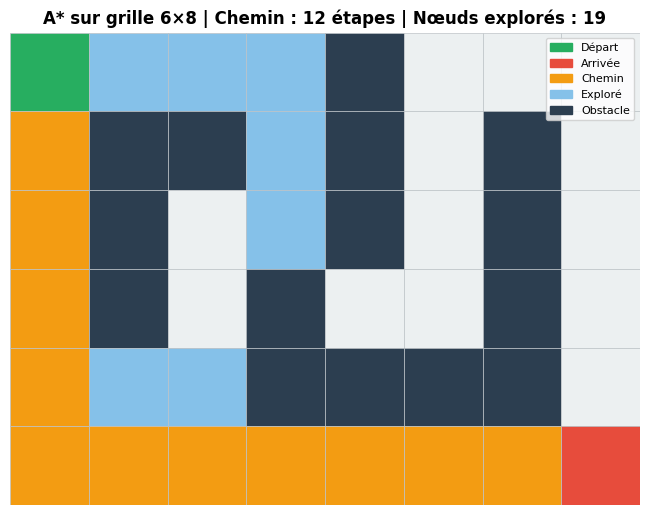

In [27]:
# --- Exercice 4 : Pathfinding sur grille avec A* ---

class GridProblem(Problem):
    """Problème de pathfinding sur une grille 2D avec obstacles.

    La grille est une liste de listes d'entiers :
      0 = cellule libre
      1 = obstacle (mur)
    L'état est un tuple (row, col).
    Les déplacements sont les 4 directions cardinales (haut, bas, gauche, droite).
    """

    DIRECTIONS = {
        'H': (-1,  0),   # Haut
        'B': ( 1,  0),   # Bas
        'G': ( 0, -1),   # Gauche
        'D': ( 0,  1),   # Droite
    }

    def __init__(self, grid, start, goal):
        super().__init__(start, goal)
        self.grid = grid
        self.rows = len(grid)
        self.cols = len(grid[0])

    def actions(self, state):
        """Retourne les directions valides depuis state (sans sortir ni toucher un mur)."""
        row, col = state
        valid = []
        for action, (dr, dc) in self.DIRECTIONS.items():
            nr, nc = row + dr, col + dc
            if 0 <= nr < self.rows and 0 <= nc < self.cols and self.grid[nr][nc] == 0:
                valid.append(action)
        return valid

    def result(self, state, action):
        """Retourne le nouvel état après déplacement."""
        row, col = state
        dr, dc = self.DIRECTIONS[action]
        return (row + dr, col + dc)


def manhattan_distance_grid(state, goal):
    """Distance Manhattan pour la grille."""
    return abs(state[0] - goal[0]) + abs(state[1] - goal[1])


def visualize_grid_search(grid, result, start, goal):
    """Visualise la grille avec le chemin et les nœuds explorés."""
    rows, cols = len(grid), len(grid[0])
    explored_set = set(result.explored_order)
    path_set = set(result.path)

    fig, ax = plt.subplots(figsize=(cols * 0.7 + 1, rows * 0.7 + 1))

    for r in range(rows):
        for c in range(cols):
            if grid[r][c] == 1:
                color = '#2C3E50'   # mur : gris foncé
            elif (r, c) == start:
                color = '#27AE60'   # départ : vert
            elif (r, c) == goal:
                color = '#E74C3C'   # arrivée : rouge
            elif (r, c) in path_set:
                color = '#F39C12'   # chemin : orange
            elif (r, c) in explored_set:
                color = '#85C1E9'   # exploré : bleu clair
            else:
                color = '#ECF0F1'   # libre : blanc cassé

            rect = plt.Rectangle((c, rows - 1 - r), 1, 1,
                                  facecolor=color, edgecolor='#BDC3C7', linewidth=0.5)
            ax.add_patch(rect)

    # Légende
    legend_items = [
        mpatches.Patch(color='#27AE60', label='Départ'),
        mpatches.Patch(color='#E74C3C', label='Arrivée'),
        mpatches.Patch(color='#F39C12', label='Chemin'),
        mpatches.Patch(color='#85C1E9', label='Exploré'),
        mpatches.Patch(color='#2C3E50', label='Obstacle'),
    ]
    ax.legend(handles=legend_items, loc='upper right', fontsize=8)

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(
        f"A* sur grille {rows}×{cols} | "
        f"Chemin : {len(result.path)-1} étapes | "
        f"Nœuds explorés : {result.nodes_expanded}",
        fontweight='bold'
    )
    plt.tight_layout()
    plt.show()


# --- Grille de test ---
grid = [
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 1, 1, 0, 1, 0, 1, 0],
    [0, 1, 0, 0, 1, 0, 1, 0],
    [0, 1, 0, 1, 0, 0, 1, 0],
    [0, 0, 0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
]

start = (0, 0)
goal  = (5, 7)

grid_problem = GridProblem(grid, start, goal)
h_grid = lambda s: manhattan_distance_grid(s, goal)

# Résoudre avec A*
result_grid = a_star_search(grid_problem, h_grid)

print(f"Problème de pathfinding sur une grille {len(grid)}×{len(grid[0])}")
print(f"Départ : {start}, Arrivée : {goal}")
print(f"Solution trouvée : {result_grid.found}")
if result_grid.found:
    print(f"Longueur du chemin : {len(result_grid.path) - 1} étapes")
    print(f"Nœuds explorés    : {result_grid.nodes_expanded}")
    print(f"Chemin : {result_grid.path}")

visualize_grid_search(grid, result_grid, start, goal)


### Exercice 5 : Pathfinding sur grille ponderee (couts de terrain)

L'exemple A* sur grille ci-dessus utilise une grille binaire (libre / obstacle) ou chaque deplacement coute 1. En pratique, les cartes ont des **terrains varies** : route rapide, herbe, boue, eau... chacun avec un cout différent. A* reste optimal a condition d'utiliser une heuristique admissible **adaptee au cout minimum de terrain**.

**Votre mission** : adapter A* pour une grille ou chaque cellule a un cout de traversee différent.

1. Créez une classe `WeightedGridProblem` qui herite de `GridProblem` et overrider `step_cost(state, action, next_state)` pour retourner le **cout de la cellule d'arrivee** (lu dans la grille de couts). La grille passee au constructeur utilise la convention : $0 = \text{obstacle intraversable}$, $k \ge 1 = \text{cout de traversee}$ (**convention inverse a l'exemple A* sur grille ci-dessus**, qui utilisait $0 = \text{libre}$, $1 = \text{mur}$).

2. Implementez une heuristique `weighted_manhattan(state, goal, min_cost)` :

   $$ h(n) = \text{Manhattan}(n, \text{goal}) \times c_{\min} $$

   ou $c_{\min}$ est le cout minimum non-nul present dans la grille. **Justifiez** pourquoi cette heuristique est admissible.

3. Testez votre implementation sur la grille de cout ci-dessous (terrain mixte : herbe = 2, boue = 3, eau profonde = 5) ou $c_{\min} = 2$. Comparez avec A* qui utilise la **Manhattan pure** (sans ponderation). Les deux algorithmes trouvent le même cout optimal, mais la version ponderee explore **strictement moins de noeuds** car son heuristique est plus informative.

4. Interpretez : pourquoi l'heuristique ponderee guide-t-elle mieux A* ? Que se passe-t-il si on multiplie par un facteur $c > c_{\min}$ (non admissible) ?

**Lien avec la théorie de la dominance** (section 7) : $h_w = c_{\min} \cdot h_{\text{Manhattan}}$ domine $h_{\text{Manhattan}}$ tant que $c_{\min} \ge 1$. Domination stricte quand $c_{\min} > 1$.


In [28]:
# --- Exercice 5 : Pathfinding sur grille ponderee ---

# Exercice: Implementer la classe WeightedGridProblem (sous-classe de GridProblem)
# class WeightedGridProblem(GridProblem):
#     """Grille ponderee : chaque cellule a un cout de traversee (entier >= 1).
#     Convention inverse de GridProblem : 0 = obstacle, k >= 1 = cout.
#     """
#
#     def actions(self, state):
#         # Meme logique que GridProblem, mais obstacle == cout 0
#         row, col = state
#         valid = []
#         for action, (dr, dc) in self.DIRECTIONS.items():
#             nr, nc = row + dr, col + dc
#             if 0 <= nr < self.rows and 0 <= nc < self.cols and self.grid[nr][nc] > 0:
#                 valid.append(action)
#         return valid
#
#     def step_cost(self, state, action, next_state):
#         # Exercice: cout = valeur de la cellule d'arrivee dans la grille
#         pass  # student fills here


# Exercice: Implementer l'heuristique ponderee
# def weighted_manhattan(state, goal, min_cost):
#     """Manhattan * min_cost : borne inferieure sur le cout restant.
#     Admissible si min_cost <= cout reel de chaque cellule.
#     """
#     # Exercice: calculer Manhattan et multiplier par min_cost
#     pass  # student fills here


# Grille ponderee de test : herbe=2, boue=3, eau profonde=5, obstacle=0
# Tous les terrains traversables ont un cout >= 2, donc min_cost = 2.
# L'heuristique ponderee (manhattan * 2) est strictement plus informative
# que la manhattan brute (manhattan * 1), tout en restant admissible.
weighted_grid = [
    [2, 2, 2, 2, 2, 2, 2, 2],
    [2, 3, 3, 3, 0, 2, 2, 2],
    [2, 3, 5, 5, 0, 2, 0, 2],
    [2, 3, 5, 5, 0, 2, 0, 2],
    [2, 3, 3, 3, 2, 2, 0, 2],
    [2, 2, 2, 2, 2, 2, 2, 2],
]
start_w = (0, 0)
goal_w = (5, 7)

# Exercice: Lancer A* avec l'heuristique ponderee et comparer avec Manhattan pure
#
# min_cost = min(v for row in weighted_grid for v in row if v > 0)  # = 2 ici
# problem_w = WeightedGridProblem(weighted_grid, start_w, goal_w)
#
# # A* avec heuristique ponderee (manhattan * min_cost)
# h_weighted = lambda s: weighted_manhattan(s, goal_w, min_cost)
# result_w = a_star_search(problem_w, h_weighted)
#
# # A* avec Manhattan pure (admissible mais moins informative)
# h_plain = lambda s: manhattan_distance_grid(s, goal_w)
# result_plain = a_star_search(problem_w, h_plain)
#
# print(f"Heuristique ponderee (x{min_cost}) : {result_w.nodes_expanded} noeuds, cout = {result_w.cost:.1f}")
# print(f"Heuristique Manhattan brute  : {result_plain.nodes_expanded} noeuds, cout = {result_plain.cost:.1f}")
# assert abs(result_w.cost - result_plain.cost) < 1e-6, "Les deux heuristiques doivent trouver le meme cout optimal"

# Exercice: Interpreter : quelle heuristique explore moins de noeuds ? Pourquoi ?
# Redigez votre analyse dans une cellule markdown ci-dessous.

print("Exercice 5 : implementez les TODO ci-dessus.")


Exercice 5 : implementez les TODO ci-dessus.


## Conclusion

### Concepts clés

| Concept | Définition |
|---------|------------|
| **Heuristique $h(n)$** | Estimation du coût restant de $n$ au but |
| **Admissible** | $h(n) \leq h^*(n)$ (ne surestime jamais) |
| **Consistante** | $h(n) \leq c(n, n') + h(n')$ (monotone) |
| **Dominance** | $h_1 \geq h_2$ : $h_1$ est plus informée |
| **f(n) = g(n) + h(n)** | Fonction d'évaluation de A* |

### Algorithmes

| Algorithme | Critère | Optimal | Mémoire |
|------------|----------|---------|----------|
| Greedy | Minimiser $h(n)$ | Non | $O(b^m)$ |
| A* | Minimiser $g(n) + h(n)$ | Oui (si $h$ consistante) | $O(b^d)$ |
| IDA* | DFS itéré par $f(n)$ | Oui | $O(bd)$ |

### Ce qu'il faut retenir

1. **L'heuristique est la clé** : une bonne heuristique peut réduire l'explosion combinatoire de plusieurs ordres de grandeur
2. **A* est l'algo de référence** : optimal avec heuristique consistante (admissible seule ne suffit pas sans ré-ouverture, cf §7), utilisable dans la plupart des cas
3. **Greedy pour la vitesse** : quand une solution « assez bonne » suffit
4. **IDA* pour la mémoire** : même optimalité que A*, avec une consommation linéaire
5. **La dominance** : une heuristique plus informée (dominante) explore toujours moins de nœuds

### Pour aller plus loin

- **Notebook suivant** : [Search-04-LocalSearch](Search-04-LocalSearch.ipynb) — Hill Climbing, Simulated Annealing, Tabu Search
- **Applications** : Voir [Sudoku-07-Norvig](../../Sudoku/Sudoku-07-Norvig-Python.ipynb) pour l'application de la propagation de contraintes (inspirée de la recherche informée)
- **Référence** : Russell & Norvig, *Artificial Intelligence: A Modern Approach*, Chapitre 3.5 — Heuristic Functions

***

**Navigation** : [<< Recherche non informée](Search-02-Uninformed.ipynb) | [Index](../README.md) | [Recherche locale >>](Search-04-LocalSearch.ipynb)


## Conclusion et perspectives

Ce notebook a présenté les algorithmes de recherche informée, qui utilisent des connaissances spécifiques du problème (heuristiques) pour guider l'exploration. L'efficacité de ces algorithmes dépend crucialement de la qualité de l'heuristique.

**Prochain notebook** : [Search-04-LocalSearch](Search-04-LocalSearch.ipynb) — Découvrez les algorithmes de recherche locale (Hill Climbing, Simulated Annealing, Tabu Search) qui explorent l'espace de recherche de manière différente, sans maintenir de frontière explicite.


### References academiques

- Hart, P.E., Nilsson, N.J. & Raphael, B. (1968). A Formal Basis for the Heuristic Determination of Minimum Cost Paths. IEEE Transactions on Systems Science and Cybernetics 4(2):100-107.
- Pohl, I. (1970). Heuristic Search Viewed as Path Finding in a Graph. Artificial Intelligence 1(3-4):193-204.
- Korf, R.E. (1985). Depth-first Iterative-Deepening: An Optimal Admissible Tree Search. Artificial Intelligence 27(1):97-109.
- Nilsson, N.J. (1980). Principles of Artificial Intelligence. Tioga Publishing.
- Russell, S. & Norvig, P. (2020). Artificial Intelligence: A Modern Approach (4th ed.). Pearson.

